# Mini Project Supervised Learning: Prediksi Risiko Kredit (Classification) & Estimasi Suku Bunga (Multiple Regression)

Notebook *end-to-end* ini mengikuti alur **Data Understanding → Data Cleaning → Feature Engineering → Exploratory Data Analysis (EDA) → Data Modeling & Evaluations (Dual Track) → Model Persistence & Streamlit App**.

## Problem Statement & Konteks Bisnis

- **Sumber Dataset:** Kaggle — [Credit Risk Dataset (`laotse/credit-risk-dataset`)](https://www.kaggle.com/datasets/laotse/credit-risk-dataset)
- **Track A — Classification (`loan_status`):**
  - Memprediksi apakah pemohon akan **gagal bayar (`1 = Default`)** atau **lunas (`0 = Non-Default`)**.
  - **Asimetri Biaya (Cost Asymmetry):** *False Negative* (memberi pinjaman ke nasabah yang gagal bayar) mengakibatkan kerugian pokok + bunga, jauh lebih mahal dibanding *False Positive* (menolak nasabah baik, hanya kehilangan peluang bunga). Karena data tidak seimbang (`78.18%` vs `21.82%`), metrik utama adalah **ROC-AUC**, **PR-AUC**, **F1-Score**, **Recall**, dan **Precision** (bukan sekadar *Accuracy*).
- **Track B — Multiple Regression (`loan_int_rate`):**
  - Memprediksi **suku bunga wajar berbasis risiko (%)** menggunakan fitur profil peminjam & pinjaman **tanpa menyertakan `loan_status`** agar bebas *target leakage*.
  - Membandingkan *Multiple Linear Regression* (`LinearRegression`, `Ridge`, `Lasso`), `KNN Regressor`, `Decision Tree Regressor`, `Random Forest Regressor`, dan `XGBoost Regressor` menggunakan metrik **R²**, **RMSE**, dan **MAE**.

## Bagian 1 — Data Understanding

### 1.1 Setup Library & Pemuatan Dataset

In [1]:
%matplotlib inline
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from xgboost import XGBClassifier, XGBRegressor

from features import (
    CLF_RAW_COLS,
    REG_RAW_COLS,
    CreditFeatureEngineer,
    build_clf_preprocessor,
    build_reg_preprocessor,
    prediksi_risiko_kredit,
    prediksi_suku_bunga,
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
DATA_PATH = "credit_risk_dataset.csv"

df = pd.read_csv(DATA_PATH)
print(f"Dataset berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df.head()

C:\Users\fmrif.RIFA_LOQ_ESSE15\OneDrive\Documents\data science\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset berhasil dimuat: 32,581 baris x 12 kolom


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Analisis 1.1 (Skema Dataset)

Dataset mentah `credit_risk_dataset.csv` berhasil dimuat dengan **`32,581` baris × `12` kolom** (11 fitur kandidat + `loan_status`), dan pada baris indeks `0` langsung terlihat tanda awal anomali data (`person_emp_length = 123.0` pada usia `22` tahun) yang perlu diaudit pada langkah berikutnya.

| Kolom | Tipe | Deskripsi | Peran |
|---|---|---|---|
| `person_age` | Numerik (`int64`) | Usia pemohon (tahun) | Fitur Input |
| `person_income` | Numerik (`int64`) | Pendapatan tahunan pemohon | Fitur Input |
| `person_home_ownership` | Kategorikal Nominal (`str`) | Status hunian (`RENT`, `MORTGAGE`, `OWN`, `OTHER`) | Fitur Input |
| `person_emp_length` | Numerik (`float64`) | Lama bekerja (tahun) | Fitur Input |
| `loan_intent` | Kategorikal Nominal (`str`) | Tujuan pinjaman (`EDUCATION`, `MEDICAL`, `VENTURE`, dll.) | Fitur Input |
| `loan_grade` | Kategorikal Ordinal (`str`) | Grade risiko (`A` teraman s.d. `G` paling berisiko) | Fitur Input |
| `loan_amnt` | Numerik (`int64`) | Nominal pinjaman | Fitur Input |
| `loan_int_rate` | Numerik (`float64`) | Suku bunga pinjaman (%) | Fitur Track A / **Target Track B** |
| `loan_status` | Biner (`0`/`1`) | Status kredit (`0 = Lunas`, `1 = Default`) | **Target Track A** |
| `loan_percent_income` | Numerik (`float64`) | Rasio pinjaman terhadap pendapatan | Fitur Input |
| `cb_person_default_on_file` | Kategorikal Biner (`str`) | Pernah tercatat gagal bayar (`N` / `Y`) | Fitur Input |
| `cb_person_cred_hist_length` | Numerik (`int64`) | Lama riwayat kredit (tahun) | Fitur Input |

### 1.2 Audit Kualitas Data (Missing Values, Duplikat, Anomali & Class Imbalance)

In [2]:
print("=== INFO TIPE DATA ===")
df.info()

print("\n=== STATISTIK DESKRIPTIF NUMERIK ===")
print(df.describe().T.round(3))

print("\n=== MISSING VALUES ===")
missing_df = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2),
})
print(missing_df[missing_df["missing_count"] > 0])

print(f"\nExact duplicate rows: {df.duplicated().sum()}")

print("\n=== DISTRIBUSI TARGET KLASIFIKASI (loan_status) ===")
target_counts = df["loan_status"].value_counts()
target_pct = (df["loan_status"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"count": target_counts, "pct": target_pct}))

print("\n=== STATISTIK TARGET REGRESI (loan_int_rate) ===")
print(df["loan_int_rate"].describe().round(3))

print("\n=== AUDIT ANOMALI DOMAIN ===")
anom_age = df[df["person_age"] > 100]
anom_emp = df[df["person_emp_length"] > 60]
anom_emp_gt_age = df[df["person_emp_length"] > df["person_age"]]
print(f"person_age > 100           : {len(anom_age)} baris -> {anom_age['person_age'].tolist()}")
print(f"person_emp_length > 60     : {len(anom_emp)} baris -> {anom_emp['person_emp_length'].tolist()}")
print(f"person_emp_length > age    : {len(anom_emp_gt_age)} baris")
anom_rows = df[(df["person_age"] > 100) | (df["person_emp_length"] > 60) | (df["person_emp_length"] > df["person_age"])]
print(anom_rows[["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_grade", "loan_status"]])
print("\nTop 5 person_income:")
print(df.nlargest(5, "person_income")[["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_status"]])

=== INFO TIPE DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB

=== STATISTIK DESKRIPT

### Analisis 1.2 (Temuan Audit Kualitas Data)

Audit terhadap `32,581` baris mengungkap temuan kunci berikut:
- **Missing Values:** Hanya ada pada 2 kolom numerik — `person_emp_length` sebanyak **`895` baris (`2.75%`)** dan `loan_int_rate` sebanyak **`3,116` baris (`9.56%`)**. Target `loan_status` dan seluruh fitur kategorikal bersih (0 missing).
- **Duplikat Persis:** Ditemukan **`165` baris duplikat identik** yang wajib dihapus sebelum *data splitting* agar tidak memicu kebocoran antara data latih dan evaluasi.
- **Ketidakseimbangan Target (`loan_status`):** Kelas `0` (Non-Default) berjumlah **`25,473` (`78.18%`)**, sedangkan kelas `1` (Default) berjumlah **`7,108` (`21.82%`)**.
- **Target Regresi (`loan_int_rate`):** Tersedia pada `29,465` baris dengan rata-rata **`11.012%`** (std `3.240%`, median `10.990%`, rentang `5.420%–23.220%`).
- **Anomali Domain Mustahil (7 baris):**
  - `5` baris dengan `person_age > 100` (`[144, 144, 123, 123, 144]`), termasuk satu baris ekstrem `person_age = 144` dengan `person_income = 6,000,000`.
  - `2` baris dengan `person_emp_length > 60` (`123.0` tahun pada pemohon berusia `22` dan `21` tahun).

## Bagian 2 — Data Cleaning

Langkah pembersihan data:
1. Menghapus baris **duplikat persis** agar tidak menggelembungkan metrik evaluasi atau menyebabkan kebocoran antar-partisi.
2. Menghapus **anomali domain yang mustahil secara logis** (`person_age > 100` atau `person_emp_length > 60`), sambil **tetap mempertahankan baris yang memiliki nilai `NaN`** pada `person_emp_length` dan `loan_int_rate`.
3. **Prinsip Anti-Leakage:** Nilai kosong pada `person_emp_length` dan `loan_int_rate` untuk Track A (Classification) **tidak diimputasi di sini**, melainkan diimputasi di dalam `Pipeline` setelah *train-test split*. Sementara untuk Track B (Regression dengan target `loan_int_rate`), baris yang kehilangan target `loan_int_rate` akan disaring pada tahap pemodelan Regresi.

In [3]:
df_clean = df.copy()
n_start = len(df_clean)

n_dup = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

valid_age_mask = df_clean["person_age"] <= 100
valid_emp_mask = df_clean["person_emp_length"].isna() | (df_clean["person_emp_length"] <= 60)
n_anom = (~(valid_age_mask & valid_emp_mask)).sum()
df_clean = df_clean[valid_age_mask & valid_emp_mask].reset_index(drop=True)

rem_emp_gt_age = (df_clean["person_emp_length"] > df_clean["person_age"]).sum()
missing_target = df_clean["loan_status"].isna().sum()

print(f"Baris awal                     : {n_start:,}")
print(f"Duplikat persis dihapus        : {n_dup:,}")
print(f"Anomali domain dihapus         : {n_anom:,}")
print(f"Baris bersih tersisa (df_clean): {len(df_clean):,}")
print(f"Sisa person_emp_length > age   : {rem_emp_gt_age}")
print(f"Missing target loan_status     : {missing_target}")
print("\nMissing values dipertahankan untuk Pipeline:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Baris awal                     : 32,581
Duplikat persis dihapus        : 165
Anomali domain dihapus         : 7
Baris bersih tersisa (df_clean): 32,409
Sisa person_emp_length > age   : 0
Missing target loan_status     : 0

Missing values dipertahankan untuk Pipeline:
person_emp_length     887
loan_int_rate        3094
dtype: int64


### Analisis Hasil Data Cleaning

- Dari `32,581` baris awal, dihapus **`165` baris duplikat** dan **`7` baris anomali domain**, menyisakan **`32,409` baris bersih (`df_clean`)** dengan `0` baris `person_emp_length > person_age` dan `0` missing pada target `loan_status`.
- Sebanyak **`887` nilai kosong pada `person_emp_length`** dan **`3,094` nilai kosong pada `loan_int_rate`** sengaja dipertahankan agar diimputasi dengan median data *training* (`SimpleImputer(strategy="median", add_indicator=True)`) di dalam `Pipeline` setelah pemisahan *Train/Val/Test* sehingga nol *data leakage*.

## Bagian 3 — Feature Engineering

Kita merancang `CreditFeatureEngineer` (didefinisikan di `features.py` agar portabel antara notebook dan aplikasi Streamlit) untuk menghasilkan **4 fitur domain keuangan baru secara *stateless* (per baris)**:
1. **`cred_hist_to_age_ratio`** = `cb_person_cred_hist_length / person_age` — Mengukur kematangan riwayat kredit relatif terhadap usia pemohon.
2. **`income_to_loan_ratio`** = `person_income / (loan_amnt + 1.0)` — Mengukur daya tutup pendapatan tahunan terhadap total pinjaman.
3. **`emp_to_age_ratio`** = `person_emp_length / person_age` — Mengukur stabilitas masa kerja terhadap usia (mempertahankan `NaN` agar diproses oleh `SimpleImputer`).
4. **`high_burden_flag`** = `1` jika `loan_percent_income >= 0.30` else `0` — Indikator beban cicilan berat (≥ 30% pendapatan).

> **Catatan Metodologi:** Transformasi *stateless* per baris boleh ditinjau pada tahap eksplorasi, sedangkan transformasi *stateful* (`SimpleImputer` dengan `add_indicator=True`, `StandardScaler`, `OrdinalEncoder`, `OneHotEncoder`) **wajib dijalankan di dalam `Pipeline` setelah *data splitting*** sehingga statistik `Train` tidak pernah bocor ke `Validation` atau `Test`.

In [4]:
fe_preview = CreditFeatureEngineer()
df_fe = fe_preview.fit_transform(df_clean)

new_cols = ["cred_hist_to_age_ratio", "income_to_loan_ratio", "emp_to_age_ratio", "high_burden_flag"]
print("Ringkasan rata-rata & median 4 fitur baru berdasarkan loan_status:")
print(df_fe.groupby("loan_status")[new_cols].agg(["mean", "median"]).round(4))
print("\nDefault rate pada high_burden_flag (0 vs 1):")
print((df_fe.groupby("high_burden_flag")["loan_status"].agg(["count", "mean"]) * [1, 100]).rename(columns={"mean": "default_rate_pct"}).round(2))

Ringkasan rata-rata & median 4 fitur baru berdasarkan loan_status:
            cred_hist_to_age_ratio         income_to_loan_ratio          \
                              mean  median                 mean  median   
loan_status                                                               
0                           0.1958  0.1739              10.6550  7.4988   
1                           0.1919  0.1690               6.3889  4.1764   

            emp_to_age_ratio         high_burden_flag         
                        mean  median             mean median  
loan_status                                                   
0                     0.1802  0.1562           0.0580    0.0  
1                     0.1518  0.1200           0.3946    0.0  

Default rate pada high_burden_flag (0 vs 1):
                  count  default_rate_pct
high_burden_flag                         
0                 28143             15.25
1                  4266             65.56


### Analisis Feature Engineering

Keempat fitur turunan memperlihatkan daya pisah yang jelas terhadap risiko gagal bayar:
- **`income_to_loan_ratio`:** Median pemohon lunas adalah **`7.4988x`** (mean `10.6550x`), jauh lebih tinggi dibanding pemohon gagal bayar dengan median **`4.1764x`** (mean `6.3889x`).
- **`high_burden_flag`:** Pemohon dengan beban cicilan normal (`< 30%` pendapatan, `28,143` orang) hanya memiliki *default rate* **`15.25%`**, sedangkan pemohon dengan beban berat (`>= 30%`, `4,266` orang) melonjak menjadi **`65.56%`** (> 4 kali lipat).
- **`emp_to_age_ratio`:** Pemohon lunas memiliki rasio masa kerja terhadap usia yang lebih tinggi (median **`0.1562`** vs **`0.1200`** pada kelompok default).

## Bagian 4 — Exploratory Data Analysis (EDA)

### 4.1 Distribusi Target & Fitur Numerik

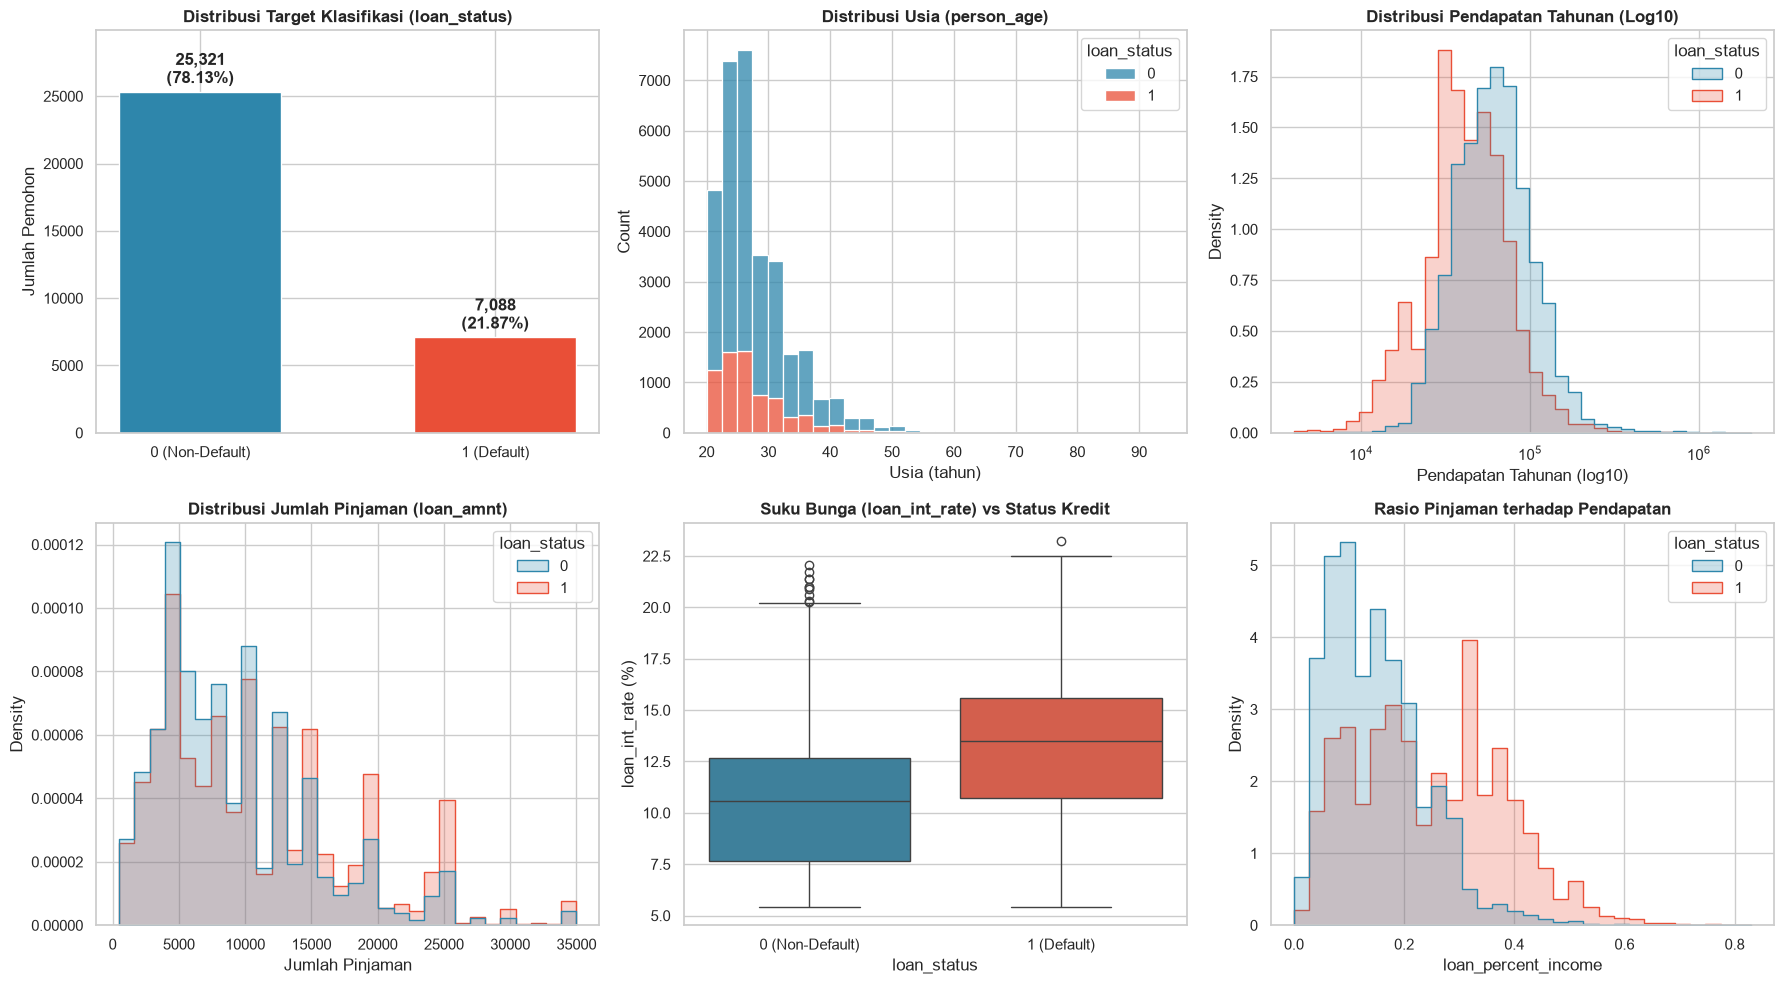

=== MEDIAN FITUR NUMERIK PER STATUS PINJAMAN ===
             person_age  person_income  person_emp_length  loan_amnt  \
loan_status                                                            
0                  26.0        60000.0                4.0     8000.0   
1                  26.0        41655.0                3.0     9600.0   

             loan_int_rate  loan_percent_income  cb_person_cred_hist_length  
loan_status                                                                  
0                    10.59                 0.13                         4.0  
1                    13.49                 0.24                         4.0  


In [5]:
palette_status = {0: "#2E86AB", 1: "#E94F37"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

# 1. Target loan_status
counts = df_clean["loan_status"].value_counts().sort_index()
bars = axes[0].bar(["0 (Non-Default)", "1 (Default)"], counts.values, color=["#2E86AB", "#E94F37"], width=0.55)
for b, cnt in zip(bars, counts.values):
    pct = cnt / len(df_clean) * 100
    axes[0].text(b.get_x() + b.get_width() / 2, cnt + 300, f"{cnt:,}\n({pct:.2f}%)", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].set_title("Distribusi Target Klasifikasi (loan_status)", fontweight="bold")
axes[0].set_ylabel("Jumlah Pemohon")

# 2. Age
sns.histplot(data=df_clean, x="person_age", hue="loan_status", bins=30, palette=palette_status, multiple="stack", ax=axes[1])
axes[1].set_title("Distribusi Usia (person_age)", fontweight="bold")
axes[1].set_xlabel("Usia (tahun)")

# 3. Income (log10)
sns.histplot(data=df_clean, x="person_income", hue="loan_status", bins=35, log_scale=True,
             palette=palette_status, element="step", common_norm=False, stat="density", ax=axes[2])
axes[2].set_title("Distribusi Pendapatan Tahunan (Log10)", fontweight="bold")
axes[2].set_xlabel("Pendapatan Tahunan (log10)")

# 4. Loan Amount
sns.histplot(data=df_clean, x="loan_amnt", hue="loan_status", bins=30,
             palette=palette_status, element="step", common_norm=False, stat="density", ax=axes[3])
axes[3].set_title("Distribusi Jumlah Pinjaman (loan_amnt)", fontweight="bold")
axes[3].set_xlabel("Jumlah Pinjaman")

# 5. Interest Rate (Target Regresi) vs loan_status
sns.boxplot(data=df_clean, x="loan_status", y="loan_int_rate", hue="loan_status",
            palette=palette_status, legend=False, ax=axes[4])
axes[4].set_xticklabels(["0 (Non-Default)", "1 (Default)"])
axes[4].set_title("Suku Bunga (loan_int_rate) vs Status Kredit", fontweight="bold")
axes[4].set_xlabel("loan_status")
axes[4].set_ylabel("loan_int_rate (%)")

# 6. Loan Percent Income
sns.histplot(data=df_clean, x="loan_percent_income", hue="loan_status", bins=30,
             palette=palette_status, element="step", common_norm=False, stat="density", ax=axes[5])
axes[5].set_title("Rasio Pinjaman terhadap Pendapatan", fontweight="bold")
axes[5].set_xlabel("loan_percent_income")

plt.tight_layout()
plt.show()

print("=== MEDIAN FITUR NUMERIK PER STATUS PINJAMAN ===")
print(df_clean.groupby("loan_status")[["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]].median().round(3))

### Analisis EDA 4.1 (Distribusi Numerik)

Berdasarkan plot distribusi dan tabel median per `loan_status` (`0` vs `1`):
- **Pendapatan (`person_income`):** Median pemohon lunas adalah **`60,000`** vs **`41,655`** pada pemohon default (lebih rendah ~`30.6%`), dengan distribusi miring kanan sehingga *log-scale* memperjelas pergeserannya.
- **Rasio Beban Pinjaman (`loan_percent_income`):** Pembeda numerik yang sangat tajam — median **`0.13`** pada Non-Default dibanding **`0.24`** pada Default (hampir 2 kali lipat), dengan ekor panjang di atas `0.30` didominasi oleh kasus default.
- **Suku Bunga (`loan_int_rate`) & Nominal (`loan_amnt`):** Pemohon default dikenakan bunga lebih tinggi (median **`13.49%`** vs **`10.59%`**) dan meminjam nominal lebih besar (median **`9,600`** vs **`8,000`**), sementara median `person_age` sama (`26.0` tahun) dan `person_emp_length` sedikit lebih rendah (`3.0` vs `4.0` tahun).

### 4.2 Default Rate (%) dan Rata-Rata Suku Bunga (%) per Kategori


--- loan_grade ---
loan_grade  count  default_pct  mean_rate
         A  10702         9.96       7.33
         B  10384        16.32      11.00
         C   6436        20.76      13.46
         D   3619        59.05      15.36
         E    963        64.49      17.01
         F    241        70.54      18.61
         G     64        98.44      20.25

--- person_home_ownership ---
person_home_ownership  count  default_pct  mean_rate
                 RENT  16374        31.61      11.46
                OTHER    106        31.13      12.03
             MORTGAGE  13366        12.62      10.50
                  OWN   2563         7.49      10.86

--- loan_intent ---
      loan_intent  count  default_pct  mean_rate
DEBTCONSOLIDATION   5189        28.68      10.99
          MEDICAL   6042        26.76      11.06
  HOMEIMPROVEMENT   3594        26.15      11.21
         PERSONAL   5496        19.89      11.00
        EDUCATION   6409        17.26      10.95
          VENTURE   5679        1

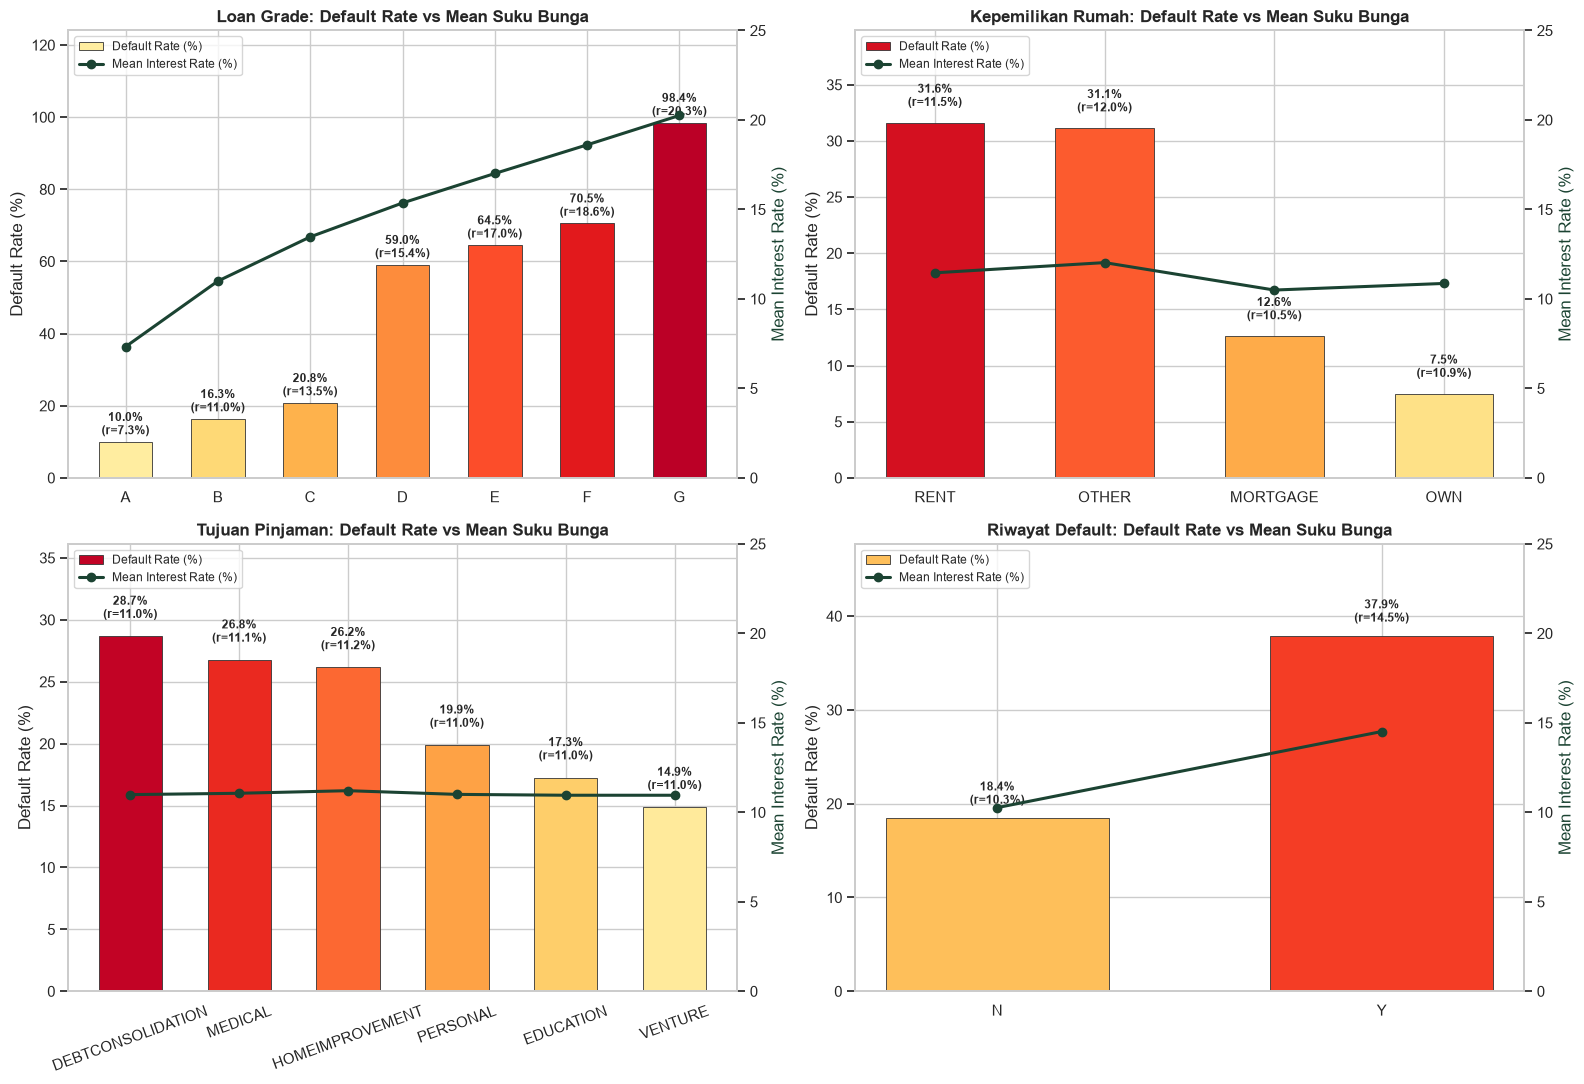

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

cat_specs = [
    ("loan_grade", ["A", "B", "C", "D", "E", "F", "G"], "Loan Grade: Default Rate vs Mean Suku Bunga", 0),
    ("person_home_ownership", None, "Kepemilikan Rumah: Default Rate vs Mean Suku Bunga", 0),
    ("loan_intent", None, "Tujuan Pinjaman: Default Rate vs Mean Suku Bunga", 20),
    ("cb_person_default_on_file", ["N", "Y"], "Riwayat Default: Default Rate vs Mean Suku Bunga", 0),
]

for ax, (col, order, title, rot) in zip(axes.ravel(), cat_specs):
    summary = (
        df_clean.groupby(col, observed=False)
        .agg(count=("loan_status", "count"), default_rate=("loan_status", "mean"), mean_rate=("loan_int_rate", "mean"))
        .reset_index()
    )
    if order is not None:
        summary[col] = pd.Categorical(summary[col], categories=order, ordered=True)
        summary = summary.sort_values(col)
    else:
        summary = summary.sort_values("default_rate", ascending=False)

    summary["default_pct"] = summary["default_rate"] * 100
    x_labels = summary[col].astype(str).tolist()
    x_pos = np.arange(len(summary))

    rank = summary["default_pct"].rank(method="first").astype(int) - 1
    palette = sns.color_palette("YlOrRd", n_colors=len(summary))
    bars = ax.bar(x_pos, summary["default_pct"], width=0.58, color=[palette[r] for r in rank],
                  edgecolor="#333333", linewidth=0.6, label="Default Rate (%)")
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.2,
            f"{row['default_pct']:.1f}%\n(r={row['mean_rate']:.1f}%)",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
        )
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    if rot:
        ax.tick_params(axis="x", rotation=rot)
    ax.set_ylim(0, max(summary["default_pct"].max() * 1.26, 15))
    ax.set_ylabel("Default Rate (%)")
    ax.set_title(title, fontweight="bold")

    ax2 = ax.twinx()
    ax2.plot(x_pos, summary["mean_rate"], color="#1B4332", marker="o", lw=2.2, label="Mean Interest Rate (%)")
    ax2.set_ylabel("Mean Interest Rate (%)", color="#1B4332")
    ax2.set_ylim(0, 25)
    ax2.grid(False)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5)

    print(f"\n--- {col} ---")
    print(summary[[col, "count", "default_pct", "mean_rate"]].round(2).to_string(index=False))

plt.tight_layout()
plt.show()

### Analisis EDA 4.2 (Pola Kategorikal & Harga Risiko)

Keempat fitur kategorikal menyimpan sinyal kuat baik untuk risiko gagal bayar (`loan_status`) maupun penetapan suku bunga (`loan_int_rate`):
- **`loan_grade`:** Menunjukkan kenaikan **monotonik sempurna** pada kedua target: dari Grade `A` (default **`9.96%`**, mean rate **`7.33%`**) → `B` (`16.32%`, `11.00%`) → `C` (`20.76%`, `13.46%`), lalu melompat drastis mulai `D` (**`59.05%`**, `15.36%`), `E` (`64.49%`, `17.01%`), `F` (`70.54%`, `18.61%`), hingga `G` (**`98.44%`**, `20.25%`). Hal ini membenarkan penggunaan `OrdinalEncoder` berurut `A < B < ... < G`.
- **`person_home_ownership`:** Penyewa (`RENT`: **`31.61%`** default) dan `OTHER` (`31.13%`) berisiko jauh lebih tinggi dibanding pemilik rumah KPR (`MORTGAGE`: `12.62%`) maupun pemilik penuh (`OWN`: **`7.49%`**).
- **`loan_intent`:** Risiko gagal bayar tertinggi terjadi pada `DEBTCONSOLIDATION` (**`28.68%`**) dan `MEDICAL` (`26.76%`), sedangkan terendah pada `VENTURE` (**`14.86%`**) dan `EDUCATION` (`17.26%`), sementara rata-rata suku bunganya relatif stabil di kisaran `10.95%–11.21%`.
- **`cb_person_default_on_file`:** Nasabah dengan riwayat gagal bayar (`Y`) memiliki tingkat default **`37.86%`** dan mean bunga **`14.52%`**, lebih dari dua kali lipat default rate kelompok `N` (**`18.44%`**, mean bunga **`10.26%`**).

### 4.3 Matriks Korelasi (Termasuk Fitur Engineered) & Peta Interaksi Risiko

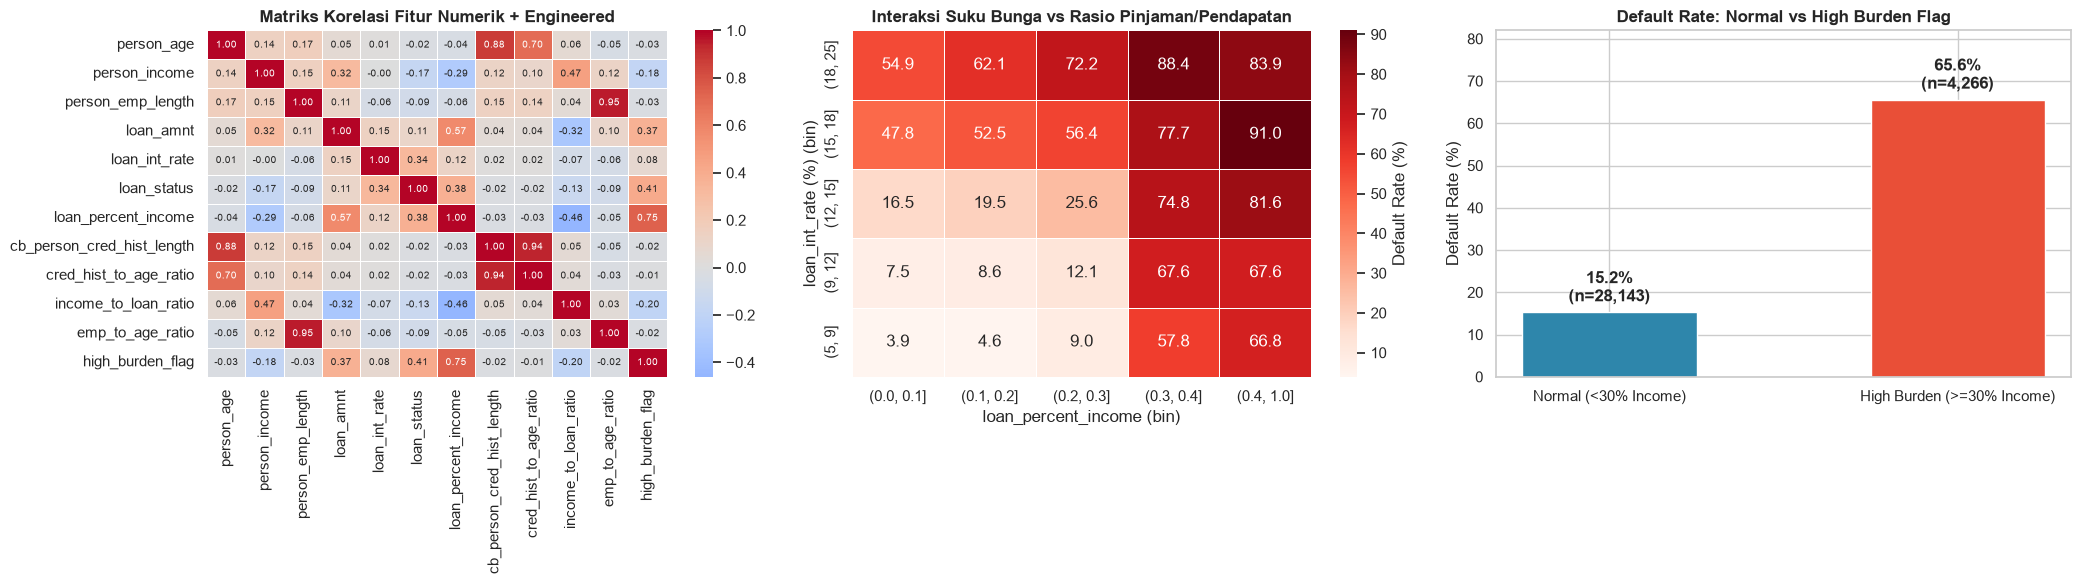

Korelasi fitur terhadap loan_status:
high_burden_flag              0.4115
loan_percent_income           0.3796
loan_int_rate                 0.3358
loan_amnt                     0.1056
cb_person_cred_hist_length   -0.0164
cred_hist_to_age_ratio       -0.0173
person_age                   -0.0218
person_emp_length            -0.0863
emp_to_age_ratio             -0.0863
income_to_loan_ratio         -0.1321
person_income                -0.1693
Name: loan_status, dtype: float64

Korelasi fitur terhadap loan_int_rate:
loan_status                   0.3358
loan_amnt                     0.1469
loan_percent_income           0.1201
high_burden_flag              0.0779
cred_hist_to_age_ratio        0.0168
cb_person_cred_hist_length    0.0159
person_age                    0.0111
person_income                -0.0010
person_emp_length            -0.0585
emp_to_age_ratio             -0.0639
income_to_loan_ratio         -0.0715
Name: loan_int_rate, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Correlation Heatmap (termasuk fitur hasil Feature Engineering)
num_corr = df_fe.select_dtypes(include=[np.number]).corr()
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4,
            annot_kws={"size": 7.5}, ax=axes[0])
axes[0].set_title("Matriks Korelasi Fitur Numerik + Engineered", fontweight="bold")

# 2. 2D Risk Interaction Heatmap: loan_percent_income vs loan_int_rate
df_tmp = df_clean[["loan_percent_income", "loan_int_rate", "loan_status"]].dropna().copy()
df_tmp["pct_inc_bin"] = pd.cut(df_tmp["loan_percent_income"], bins=[0, 0.1, 0.2, 0.3, 0.4, 1.0])
df_tmp["int_rate_bin"] = pd.cut(df_tmp["loan_int_rate"], bins=[5, 9, 12, 15, 18, 25])
risk_pivot = df_tmp.pivot_table(index="int_rate_bin", columns="pct_inc_bin", values="loan_status", aggfunc="mean", observed=False) * 100
sns.heatmap(risk_pivot.sort_index(ascending=False), annot=True, fmt=".1f", cmap="Reds", linewidths=0.5, ax=axes[1],
            cbar_kws={"label": "Default Rate (%)"})
axes[1].set_title("Interaksi Suku Bunga vs Rasio Pinjaman/Pendapatan", fontweight="bold")
axes[1].set_xlabel("loan_percent_income (bin)")
axes[1].set_ylabel("loan_int_rate (%) (bin)")

# 3. Default Rate by high_burden_flag
hb = df_fe.groupby("high_burden_flag")["loan_status"].agg(["count", "mean"]).reset_index()
hb["default_pct"] = hb["mean"] * 100
bars = axes[2].bar(["Normal (<30% Income)", "High Burden (>=30% Income)"], hb["default_pct"],
                   color=["#2E86AB", "#E94F37"], width=0.5)
for bar, (_, row) in zip(bars, hb.iterrows()):
    axes[2].text(bar.get_x() + bar.get_width() / 2, row["default_pct"] + 1.5,
                 f"{row['default_pct']:.1f}%\n(n={int(row['count']):,})", ha="center", va="bottom", fontweight="bold")
axes[2].set_ylim(0, hb["default_pct"].max() * 1.25)
axes[2].set_title("Default Rate: Normal vs High Burden Flag", fontweight="bold")
axes[2].set_ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

print("Korelasi fitur terhadap loan_status:")
print(num_corr["loan_status"].drop("loan_status").sort_values(ascending=False).round(4))
print("\nKorelasi fitur terhadap loan_int_rate:")
print(num_corr["loan_int_rate"].drop("loan_int_rate").sort_values(ascending=False).round(4))

### Analisis EDA 4.3 (Korelasi & Interaksi Fitur)

- **Korelasi terhadap `loan_status`:** Fitur rekayasa **`high_burden_flag`** mencatat korelasi linear tertinggi (**`+0.4115`**), melampaui fitur asalnya `loan_percent_income` (**`+0.3796`**) dan `loan_int_rate` (**`+0.3358`**). Sebaliknya, `person_income` (`-0.1693`) dan `income_to_loan_ratio` (`-0.1321`) berkorelasi negatif terhadap risiko gagal bayar.
- **Peta Interaksi 2D:** Kombinasi suku bunga tinggi (`>15%`) dan rasio pinjaman terhadap pendapatan `>= 0.30` membentuk zona merah dengan *default rate* sangat tinggi, mengonfirmasi hubungan non-linear yang cocok ditangkap model berbasis *tree ensemble*.
- **Korelasi terhadap `loan_int_rate`:** Korelasi numerik dengan fitur input lain relatif kecil (`loan_amnt` `+0.1469`, `loan_percent_income` `+0.1201`), mengindikasikan bahwa variabel kategorikal (`loan_grade` dan `cb_person_default_on_file`) adalah penentu utama dalam estimasi suku bunga pada Track B.

## Bagian 5 — Data Modeling and Evaluations

Pada bagian ini kita membangun dan membandingkan **dua track Supervised Learning** pada dataset yang sama:
- **Track A (Classification):** Memprediksi gagal bayar (`loan_status`) menggunakan 8 model klasifikasi (`Dummy`, `Logistic Regression`, `KNN`, `Decision Tree`, `Random Forest`, `XGBoost`), diikuti tuning (`GridSearchCV`, `RandomizedSearchCV`, `Optuna`), *Threshold Tuning*, *Bootstrap 95% CI*, *Slice Error Analysis*, dan *Feature Importance*.
- **Track B (Multiple Regression):** Memprediksi suku bunga wajar (`loan_int_rate`) menggunakan 9 model regresi (`DummyRegressor`, `LinearRegression`, `Ridge`, `Lasso`, `KNN Regressor`, `Decision Tree Regressor`, `Random Forest Regressor`, `XGBoost Regressor`), diikuti tuning (`RandomizedSearchCV`), *Bootstrap 95% CI*, dan analisis residual.

### Track A — Classification (`loan_status`: Prediksi Risiko Gagal Bayar)

#### 5A.1 Stratified Split (64% Train / 16% Val / 20% Test) & Verifikasi Pipeline Bebas Leakage

In [8]:
X_clf = df_clean[CLF_RAW_COLS].copy()
y_clf = df_clean["loan_status"].astype(int)

X_clf_tv, X_clf_test, y_clf_tv, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.20, stratify=y_clf, random_state=RANDOM_STATE
)
X_clf_train, X_clf_val, y_clf_train, y_clf_val = train_test_split(
    X_clf_tv, y_clf_tv, test_size=0.20, stratify=y_clf_tv, random_state=RANDOM_STATE
)

split_clf_df = pd.DataFrame([
    {"Split": "Train", "Rows": len(X_clf_train), "Pct_Total": len(X_clf_train) / len(df_clean) * 100, "Default_Rate_Pct": y_clf_train.mean() * 100},
    {"Split": "Validation", "Rows": len(X_clf_val), "Pct_Total": len(X_clf_val) / len(df_clean) * 100, "Default_Rate_Pct": y_clf_val.mean() * 100},
    {"Split": "Test (Hold-out)", "Rows": len(X_clf_test), "Pct_Total": len(X_clf_test) / len(df_clean) * 100, "Default_Rate_Pct": y_clf_test.mean() * 100},
])
print("=== STRATIFIED SPLIT TRACK A (CLASSIFICATION) ===")
print(split_clf_df.round(2).to_string(index=False))

preview_clf_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_clf_preprocessor()),
])
X_clf_train_t = preview_clf_pipe.fit_transform(X_clf_train)
X_clf_val_t = preview_clf_pipe.transform(X_clf_val)
clf_feat_names = preview_clf_pipe.named_steps["prep"].get_feature_names_out()

print(f"\nShape Train -> Val setelah transform: {X_clf_train_t.shape} -> {X_clf_val_t.shape}")
print(f"Total NaN Train / Val               : {np.isnan(X_clf_train_t).sum()} / {np.isnan(X_clf_val_t).sum()}")
print(f"Jumlah fitur akhir                  : {len(clf_feat_names)}")

=== STRATIFIED SPLIT TRACK A (CLASSIFICATION) ===
          Split  Rows  Pct_Total  Default_Rate_Pct
          Train 20741       64.0             21.87
     Validation  5186       16.0             21.87
Test (Hold-out)  6482       20.0             21.88

Shape Train -> Val setelah transform: (20741, 26) -> (5186, 26)
Total NaN Train / Val               : 0 / 0
Jumlah fitur akhir                  : 26


### Analisis 5A.1 (Verifikasi Split & Pipeline Klasifikasi)

- Pembagian stratifikasi menjaga proporsi target sangat stabil: **Train `20,741` baris (`64.0%`, default `21.87%`)**, **Validation `5,186` baris (`16.0%`, default `21.87%`)**, dan **Test Hold-out `6,482` baris (`20.0%`, default `21.88%`)**.
- Pipeline preprocessing hanya di-*fit* pada `X_clf_train`, mentransformasi 11 fitur mentah menjadi **`26` fitur numerik bersih** (`11` numerik terstandarisasi + `3` *missingness indicator* dari `SimpleImputer(add_indicator=True)` + `2` ordinal + `10` one-hot) dengan **`0` nilai `NaN`** di Train maupun Validation.

#### 5A.2 Perbandingan 8 Model Klasifikasi (5-Fold Stratified CV)

In [9]:
cv5_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

clf_models = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Logistic Regression (Balanced)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN (k=11)": KNeighborsClassifier(n_neighbors=11, n_jobs=-1),
    "Decision Tree (Unregularized)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Decision Tree (Regularized)": DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

clf_records = []
clf_fitted = {}
clf_val_probs = {}

for name, estimator in clf_models.items():
    pipe = Pipeline([
        ("fe", CreditFeatureEngineer()),
        ("prep", build_clf_preprocessor()),
        ("clf", estimator),
    ])
    cv_res = cross_validate(
        pipe, X_clf_train, y_clf_train, cv=cv5_clf,
        scoring={"roc_auc": "roc_auc", "f1": "f1"}, n_jobs=1
    )

    t0 = time.perf_counter()
    pipe.fit(X_clf_train, y_clf_train)
    train_time_s = time.perf_counter() - t0

    t1 = time.perf_counter()
    val_probs = pipe.predict_proba(X_clf_val)[:, 1]
    val_preds = (val_probs >= 0.5).astype(int)
    infer_time_ms = (time.perf_counter() - t1) * 1000.0

    train_preds = pipe.predict(X_clf_train)
    clf_fitted[name] = pipe
    clf_val_probs[name] = val_probs

    clf_records.append({
        "Model": name,
        "CV_ROC_AUC": cv_res["test_roc_auc"].mean(),
        "CV_F1": cv_res["test_f1"].mean(),
        "Val_ROC_AUC": roc_auc_score(y_clf_val, val_probs),
        "Val_PR_AUC": average_precision_score(y_clf_val, val_probs),
        "Val_F1": f1_score(y_clf_val, val_preds, zero_division=0),
        "Val_Recall": recall_score(y_clf_val, val_preds, zero_division=0),
        "Val_Precision": precision_score(y_clf_val, val_preds, zero_division=0),
        "Train_Acc": accuracy_score(y_clf_train, train_preds),
        "Val_Acc": accuracy_score(y_clf_val, val_preds),
        "Train_Time_s": train_time_s,
        "Infer_Time_ms": infer_time_ms,
    })

clf_results_df = pd.DataFrame(clf_records).sort_values("Val_ROC_AUC", ascending=False).reset_index(drop=True)
print("=== PERBANDINGAN 8 MODEL KLASIFIKASI ===")
print(clf_results_df.round(4).to_string(index=False))

=== PERBANDINGAN 8 MODEL KLASIFIKASI ===
                         Model  CV_ROC_AUC  CV_F1  Val_ROC_AUC  Val_PR_AUC  Val_F1  Val_Recall  Val_Precision  Train_Acc  Val_Acc  Train_Time_s  Infer_Time_ms
                       XGBoost      0.9432 0.8338       0.9480      0.9012  0.8192      0.7072         0.9733     0.9454   0.9317        0.3096        26.4748
                 Random Forest      0.9272 0.8270       0.9320      0.8795  0.8082      0.6949         0.9657     1.0000   0.9279        0.9842       108.8463
   Decision Tree (Regularized)      0.9082 0.8062       0.9075      0.8439  0.7988      0.6808         0.9662     0.9302   0.9250        0.1694        17.4580
                    KNN (k=11)      0.8740 0.7131       0.8790      0.7594  0.7035      0.5891         0.8732     0.9031   0.8914        0.0883       163.9807
Logistic Regression (Balanced)      0.8735 0.6358       0.8728      0.7226  0.6452      0.7698         0.5553     0.8063   0.8149        0.1508        17.5088
     

### Analisis 5A.2 (Perbandingan Baseline & Multi-Model Klasifikasi)

Perbandingan 8 model pada 5-Fold Stratified CV dan Validation Set menunjukkan hierarki performa yang tegas:
- **Naive & Linear Baselines:** `Dummy` menghasilkan `Val_Acc = 0.7813` dengan `Val_F1 = 0.0000` (membuktikan *Accuracy* saja menyesatkan). `Logistic Regression` mencapai `CV_ROC_AUC = 0.8724` / `Val_ROC_AUC = 0.8719`, sedangkan versi `Balanced` menaikkan `Val_Recall` dari `0.5459` ke `0.7698` dengan kompensasi penurunan `Val_Precision` ke `0.5553`.
- **KNN (`k=11`):** Mencapai `Val_ROC_AUC = 0.8790` dan `Val_F1 = 0.7035`, namun memiliki latensi inferensi paling lambat (`98.25 ms` untuk `5,186` baris) karena komputasi jarak ke seluruh titik latih.
- **Bukti Overfitting pada Single Tree:** `Decision Tree (Unregularized)` menghafal data latih (`Train_Acc = 1.0000`) namun anjlok di validasi (`Val_Acc = 0.8866`, `Val_ROC_AUC = 0.8404`). Pembatasan kedalaman (`Decision Tree (Regularized)`, `max_depth=7, min_samples_leaf=20`) berhasil menaikkan `Val_ROC_AUC` secara drastis ke **`0.9075`** (`Val_F1 = 0.7988`).
- **Dominasi Tree Ensembles:** `Random Forest` mencetak `Val_ROC_AUC = 0.9320` (`Val_F1 = 0.8082`), sementara **`XGBoost`** unggul di semua metrik utama (`CV_ROC_AUC = 0.9432`, `Val_ROC_AUC = 0.9480`, `Val_PR_AUC = 0.9012`, `Val_F1 = 0.8192`, `Val_Precision = 0.9733`) sekaligus cepat saat latih (`0.27 s`) dan inferensi (`20.37 ms`).

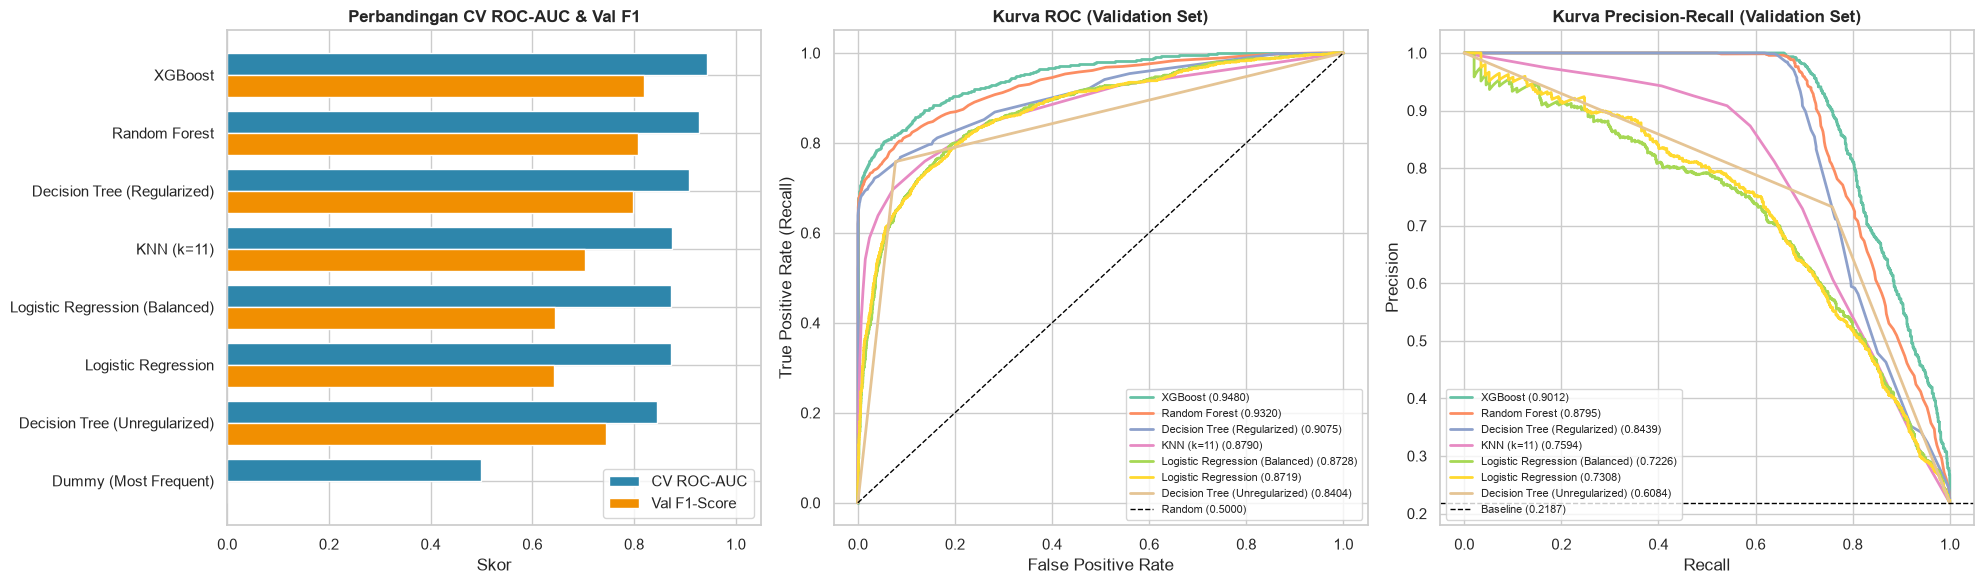

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Bar chart CV ROC-AUC & Val F1
plot_clf = clf_results_df.sort_values("CV_ROC_AUC", ascending=True)
y_pos = np.arange(len(plot_clf))
h = 0.38
axes[0].barh(y_pos + h / 2, plot_clf["CV_ROC_AUC"], height=h, label="CV ROC-AUC", color="#2E86AB")
axes[0].barh(y_pos - h / 2, plot_clf["Val_F1"], height=h, label="Val F1-Score", color="#F18F01")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_clf["Model"])
axes[0].set_xlim(0, 1.05)
axes[0].set_title("Perbandingan CV ROC-AUC & Val F1", fontweight="bold")
axes[0].set_xlabel("Skor")
axes[0].legend(loc="lower right")

# 2. ROC Curves
for name in clf_results_df["Model"]:
    if name.startswith("Dummy"):
        continue
    fpr, tpr, _ = roc_curve(y_clf_val, clf_val_probs[name])
    auc_v = roc_auc_score(y_clf_val, clf_val_probs[name])
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} ({auc_v:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random (0.5000)")
axes[1].set_title("Kurva ROC (Validation Set)", fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc="lower right", fontsize=8)

# 3. PR Curves
base_prev = y_clf_val.mean()
for name in clf_results_df["Model"]:
    if name.startswith("Dummy"):
        continue
    prec, rec, _ = precision_recall_curve(y_clf_val, clf_val_probs[name])
    ap_v = average_precision_score(y_clf_val, clf_val_probs[name])
    axes[2].plot(rec, prec, lw=2, label=f"{name} ({ap_v:.4f})")
axes[2].axhline(base_prev, color="black", linestyle="--", lw=1, label=f"Baseline ({base_prev:.4f})")
axes[2].set_title("Kurva Precision-Recall (Validation Set)", fontweight="bold")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

### Analisis Visualisasi Kurva ROC & Precision-Recall

- Pada **Kurva ROC**, `XGBoost` (`0.9480`) dan `Random Forest` (`0.9320`) merapat kuat ke sudut kiri-atas dibanding `Logistic Regression` (`0.8719`) maupun `KNN` (`0.8790`).
- Keunggulan tersebut semakin mencolok pada **Kurva Precision-Recall** (metrik sensitif ketidakseimbangan kelas): `XGBoost` mempertahankan `Val PR-AUC = 0.9012` (> 4x lipat baseline prevalensi `0.2187`) dan menjaga presisi sangat tinggi hingga *recall* sekitar `0.70`, membuktikan kemampuannya menyaring gagal bayar tanpa banyak alarm palsu.

#### 5A.3 Hyperparameter Tuning (GridSearchCV, RandomizedSearchCV, dan Optuna)

In [11]:
logreg_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_clf_preprocessor()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
grid_logreg = GridSearchCV(
    logreg_pipe,
    param_grid={"clf__C": [0.01, 0.1, 1.0, 10.0], "clf__class_weight": [None, "balanced"]},
    cv=cv5_clf,
    scoring="roc_auc",
    n_jobs=1,
    refit=True,
)
t0 = time.perf_counter()
grid_logreg.fit(X_clf_train, y_clf_train)
t_lr = time.perf_counter() - t0

best_logreg_pipe = grid_logreg.best_estimator_
val_probs_lr_t = best_logreg_pipe.predict_proba(X_clf_val)[:, 1]
val_preds_lr_t = (val_probs_lr_t >= 0.5).astype(int)

print(f"GridSearchCV LogReg ({t_lr:.2f}s) | Best Params: {grid_logreg.best_params_}")
print(f"CV ROC-AUC={grid_logreg.best_score_:.4f} | Val ROC-AUC={roc_auc_score(y_clf_val, val_probs_lr_t):.4f} | Val PR-AUC={average_precision_score(y_clf_val, val_probs_lr_t):.4f} | Val F1={f1_score(y_clf_val, val_preds_lr_t):.4f}")

GridSearchCV LogReg (6.24s) | Best Params: {'clf__C': 0.1, 'clf__class_weight': 'balanced'}
CV ROC-AUC=0.8735 | Val ROC-AUC=0.8729 | Val PR-AUC=0.7221 | Val F1=0.6462


### Analisis Tuning Logistic Regression (GridSearchCV)

`GridSearchCV` (`3.94 s`) memilih `C = 0.1` dan `class_weight = 'balanced'`, menghasilkan `CV ROC-AUC = 0.8735` dan `Val ROC-AUC = 0.8729` (`Val F1 = 0.6462`). Karena model linear dibatasi oleh pemisahan *hyperplane* datar, tuning regularisasi hanya memberi peningkatan marjinal dibanding model berbasis pohon.

In [12]:
cv3_clf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_clf_preprocessor()),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_param_dist = {
    "clf__n_estimators": [150, 200, 300, 400],
    "clf__max_depth": [8, 12, 16, 20, None],
    "clf__min_samples_split": [2, 5, 10, 20],
    "clf__min_samples_leaf": [1, 2, 5, 10],
    "clf__max_features": ["sqrt", "log2", 0.5],
    "clf__class_weight": [None, "balanced_subsample"],
}
rand_rf = RandomizedSearchCV(
    rf_pipe,
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=cv3_clf,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True,
)
t0 = time.perf_counter()
rand_rf.fit(X_clf_train, y_clf_train)
t_rf = time.perf_counter() - t0

best_rf_pipe = rand_rf.best_estimator_
val_probs_rf_t = best_rf_pipe.predict_proba(X_clf_val)[:, 1]
val_preds_rf_t = (val_probs_rf_t >= 0.5).astype(int)

print(f"RandomizedSearchCV RF ({t_rf:.2f}s) | Best Params: {rand_rf.best_params_}")
print(f"CV ROC-AUC (3-fold)={rand_rf.best_score_:.4f} | Val ROC-AUC={roc_auc_score(y_clf_val, val_probs_rf_t):.4f} | Val PR-AUC={average_precision_score(y_clf_val, val_probs_rf_t):.4f} | Val F1={f1_score(y_clf_val, val_preds_rf_t):.4f}")

RandomizedSearchCV RF (66.16s) | Best Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.5, 'clf__max_depth': 16, 'clf__class_weight': 'balanced_subsample'}
CV ROC-AUC (3-fold)=0.9301 | Val ROC-AUC=0.9321 | Val PR-AUC=0.8810 | Val F1=0.8103


### Analisis Tuning Random Forest (RandomizedSearchCV)

`RandomizedSearchCV` (15 iterasi, 3-fold CV dalam `~55 s`) menemukan kombinasi optimal `n_estimators = 300`, `max_depth = 16`, `min_samples_split = 10`, `min_samples_leaf = 1`, `max_features = 0.5`, dan `class_weight = 'balanced_subsample'`, meningkatkan performa validasi dari `Val ROC-AUC = 0.9320` → **`0.9321`**, `Val PR-AUC = 0.8795` → **`0.8810`**, serta `Val F1 = 0.8082` → **`0.8103`** sembari menahan kedalaman pohon agar tidak *overfit* total.

Optuna XGBoost (59.84s, 25 trials, 5-fold CV) | Best CV ROC-AUC=0.9457
Best Params: {'n_estimators': 417, 'max_depth': 4, 'learning_rate': 0.16633774901409468, 'subsample': 0.9774944316506684, 'colsample_bytree': 0.8245804112552702, 'min_child_weight': 2, 'reg_alpha': 0.002735922117693012, 'reg_lambda': 0.005876731461549031, 'scale_pos_weight': 2.1259618949988845}
Val ROC-AUC=0.9495 | Val PR-AUC=0.9047 | Val F1=0.8238 | Val Recall=0.7646 | Val Precision=0.8929

=== DEFAULT VS TUNED (VALIDATION SET) ===
                       Model  Val_ROC_AUC  Val_PR_AUC
            LogReg (Default)       0.8719      0.7308
         LogReg (GridSearch)       0.8729      0.7221
     Random Forest (Default)       0.9320      0.8795
Random Forest (RandomSearch)       0.9321      0.8810
           XGBoost (Default)       0.9480      0.9012
            XGBoost (Optuna)       0.9495      0.9047


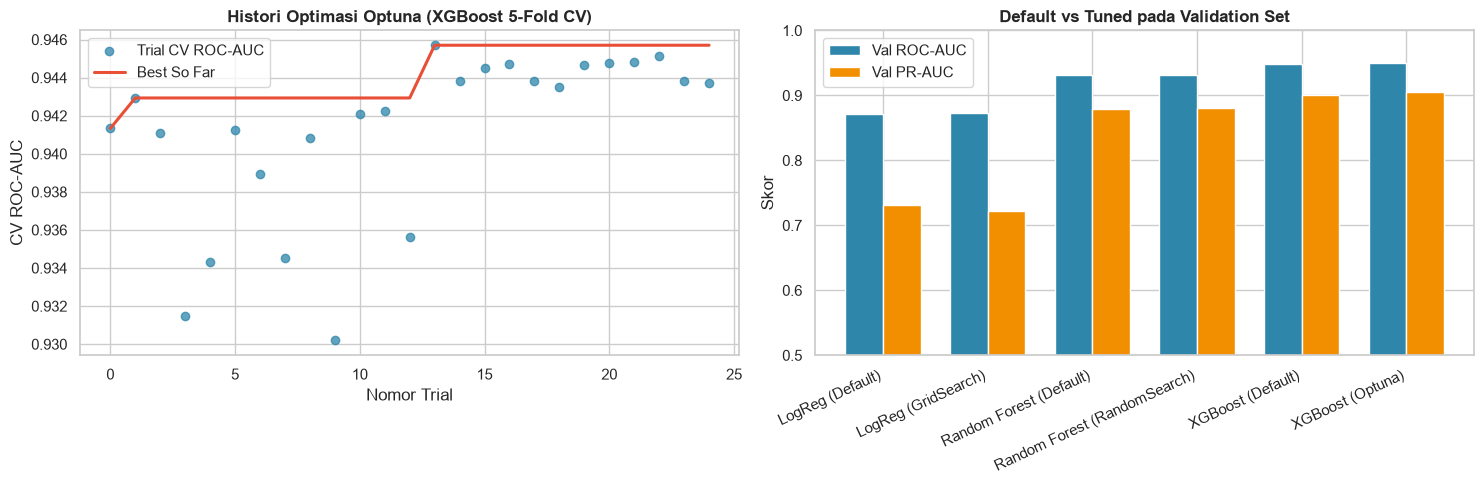

In [13]:
def xgb_clf_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 9),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.5),
    }
    pipe = Pipeline([
        ("fe", CreditFeatureEngineer()),
        ("prep", build_clf_preprocessor()),
        ("clf", XGBClassifier(
            **params,
            tree_method="hist",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])
    scores = cross_validate(pipe, X_clf_train, y_clf_train, cv=cv5_clf, scoring="roc_auc", n_jobs=1)
    return scores["test_score"].mean()


t0 = time.perf_counter()
study_clf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_clf.optimize(xgb_clf_objective, n_trials=25)
t_xgb = time.perf_counter() - t0

best_xgb_params = study_clf.best_params
best_xgb_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_clf_preprocessor()),
    ("clf", XGBClassifier(
        **best_xgb_params,
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
best_xgb_pipe.fit(X_clf_train, y_clf_train)
val_probs_xgb_t = best_xgb_pipe.predict_proba(X_clf_val)[:, 1]
val_preds_xgb_t = (val_probs_xgb_t >= 0.5).astype(int)

print(f"Optuna XGBoost ({t_xgb:.2f}s, 25 trials, 5-fold CV) | Best CV ROC-AUC={study_clf.best_value:.4f}")
print("Best Params:", best_xgb_params)
print(f"Val ROC-AUC={roc_auc_score(y_clf_val, val_probs_xgb_t):.4f} | Val PR-AUC={average_precision_score(y_clf_val, val_probs_xgb_t):.4f} | Val F1={f1_score(y_clf_val, val_preds_xgb_t):.4f} | Val Recall={recall_score(y_clf_val, val_preds_xgb_t):.4f} | Val Precision={precision_score(y_clf_val, val_preds_xgb_t):.4f}")

compare_tune_clf = pd.DataFrame([
    {"Model": "LogReg (Default)", "Val_ROC_AUC": roc_auc_score(y_clf_val, clf_val_probs["Logistic Regression"]), "Val_PR_AUC": average_precision_score(y_clf_val, clf_val_probs["Logistic Regression"])},
    {"Model": "LogReg (GridSearch)", "Val_ROC_AUC": roc_auc_score(y_clf_val, val_probs_lr_t), "Val_PR_AUC": average_precision_score(y_clf_val, val_probs_lr_t)},
    {"Model": "Random Forest (Default)", "Val_ROC_AUC": roc_auc_score(y_clf_val, clf_val_probs["Random Forest"]), "Val_PR_AUC": average_precision_score(y_clf_val, clf_val_probs["Random Forest"])},
    {"Model": "Random Forest (RandomSearch)", "Val_ROC_AUC": roc_auc_score(y_clf_val, val_probs_rf_t), "Val_PR_AUC": average_precision_score(y_clf_val, val_probs_rf_t)},
    {"Model": "XGBoost (Default)", "Val_ROC_AUC": roc_auc_score(y_clf_val, clf_val_probs["XGBoost"]), "Val_PR_AUC": average_precision_score(y_clf_val, clf_val_probs["XGBoost"])},
    {"Model": "XGBoost (Optuna)", "Val_ROC_AUC": roc_auc_score(y_clf_val, val_probs_xgb_t), "Val_PR_AUC": average_precision_score(y_clf_val, val_probs_xgb_t)},
])
print("\n=== DEFAULT VS TUNED (VALIDATION SET) ===")
print(compare_tune_clf.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
trials_df = study_clf.trials_dataframe()
trials_df["best_so_far"] = trials_df["value"].cummax()
axes[0].scatter(trials_df["number"], trials_df["value"], alpha=0.75, color="#2E86AB", label="Trial CV ROC-AUC")
axes[0].plot(trials_df["number"], trials_df["best_so_far"], color="#E94F37", lw=2.2, label="Best So Far")
axes[0].set_title("Histori Optimasi Optuna (XGBoost 5-Fold CV)", fontweight="bold")
axes[0].set_xlabel("Nomor Trial")
axes[0].set_ylabel("CV ROC-AUC")
axes[0].legend()

x_idx = np.arange(len(compare_tune_clf))
w = 0.36
axes[1].bar(x_idx - w / 2, compare_tune_clf["Val_ROC_AUC"], width=w, label="Val ROC-AUC", color="#2E86AB")
axes[1].bar(x_idx + w / 2, compare_tune_clf["Val_PR_AUC"], width=w, label="Val PR-AUC", color="#F18F01")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(compare_tune_clf["Model"], rotation=25, ha="right")
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Default vs Tuned pada Validation Set", fontweight="bold")
axes[1].set_ylabel("Skor")
axes[1].legend()

plt.tight_layout()
plt.show()

### Analisis Tuning XGBoost (Optuna) & Pemilihan Model Klasifikasi Terbaik

- `Optuna` (25 trial, 5-fold Stratified CV) meningkatkan performa `XGBoost` dari `CV ROC-AUC = 0.9432` → **`0.9457`**, `Val ROC-AUC = 0.9480` → **`0.9495`**, `Val PR-AUC = 0.9012` → **`0.9047`**, dan `Val F1 = 0.8192` → **`0.8238`**.
- Penggunaan bobot ketidakseimbangan `scale_pos_weight ≈ 2.13` bersama `max_depth = 4`, `n_estimators = 417`, dan `learning_rate ≈ 0.166` berhasil mendongkrak **Recall validasi dari `0.7072` menjadi `0.7646`** sambil mempertahankan `Precision = 0.8929`. **Tuned XGBoost** dipilih sebagai juara Track A.

#### 5A.4 Learning Curve & Threshold Tuning pada Validation Set

=== LEARNING CURVE (TUNED XGBOOST) ===
 Train_Size  Train_ROC_AUC  CV_ROC_AUC    Gap
       1382         1.0000      0.9049 0.0951
       3871         1.0000      0.9235 0.0765
       6360         0.9999      0.9319 0.0680
       8849         0.9995      0.9378 0.0616
      11338         0.9983      0.9423 0.0560
      13827         0.9971      0.9424 0.0547


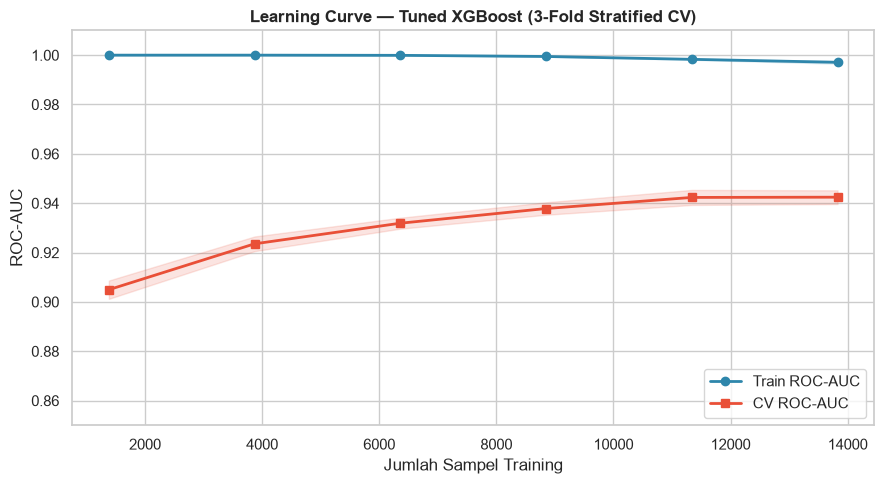

In [14]:
train_sizes, train_scores, val_scores = learning_curve(
    clone(best_xgb_pipe),
    X_clf_train,
    y_clf_train,
    cv=cv3_clf,
    train_sizes=np.linspace(0.1, 1.0, 6),
    scoring="roc_auc",
    n_jobs=1,
)
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

lc_df = pd.DataFrame({
    "Train_Size": train_sizes,
    "Train_ROC_AUC": train_mean,
    "CV_ROC_AUC": val_mean,
    "Gap": train_mean - val_mean,
})
print("=== LEARNING CURVE (TUNED XGBOOST) ===")
print(lc_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, "o-", color="#2E86AB", lw=2, label="Train ROC-AUC")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#2E86AB")
ax.plot(train_sizes, val_mean, "s-", color="#E94F37", lw=2, label="CV ROC-AUC")
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#E94F37")
ax.set_title("Learning Curve — Tuned XGBoost (3-Fold Stratified CV)", fontweight="bold")
ax.set_xlabel("Jumlah Sampel Training")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.85, 1.01)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Analisis Learning Curve Klasifikasi

- Pada `1,382` sampel latih, `CV ROC-AUC` masih `0.9049` (`Gap = 0.0951`). Seiring penambahan data latih ke `13,827` sampel, `CV ROC-AUC` naik konsisten ke **`0.9424`** dengan celah menyempit menjadi **`0.0547`**.
- Kurva sudah mulai melandai antara `11,338` (`0.9423`) dan `13,827` (`0.9424`), menandakan kapasitas data latih sudah sangat memadai tanpa indikasi *underfitting* maupun *overfitting* berlebihan.

=== THRESHOLD TUNING (VALIDATION SET) ===
               Kebijakan  threshold  precision  recall     f1  accuracy
          Default (0.50)       0.50     0.8929  0.7646 0.8238    0.9285
       F1-Optimal (0.60)       0.60     0.9479  0.7381 0.8299    0.9339
High-Recall >=80% (0.38)       0.38     0.8174  0.8016 0.8094    0.9175


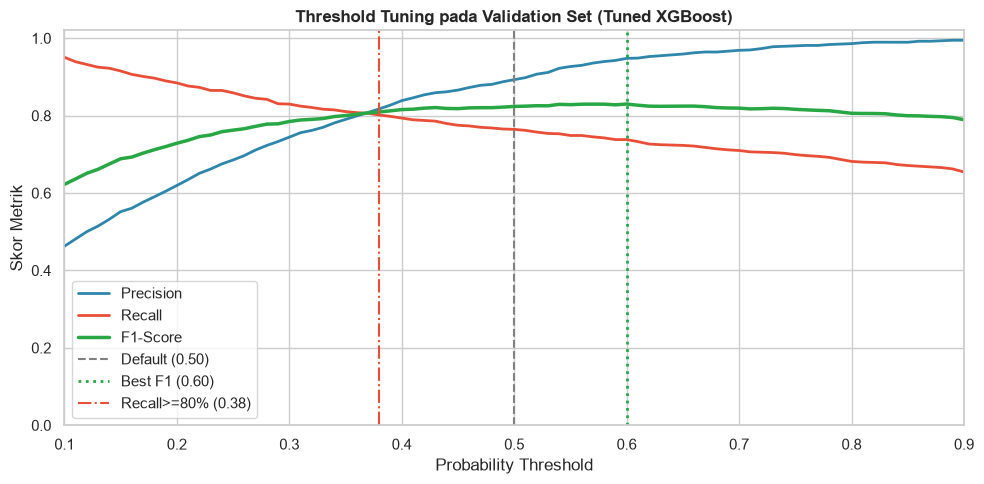

In [15]:
thresholds = np.arange(0.10, 0.91, 0.01)
thresh_rows = []
for th in thresholds:
    preds = (val_probs_xgb_t >= th).astype(int)
    thresh_rows.append({
        "threshold": round(float(th), 2),
        "precision": precision_score(y_clf_val, preds, zero_division=0),
        "recall": recall_score(y_clf_val, preds, zero_division=0),
        "f1": f1_score(y_clf_val, preds, zero_division=0),
        "accuracy": accuracy_score(y_clf_val, preds),
    })

thresh_df = pd.DataFrame(thresh_rows)
best_idx_f1 = thresh_df["f1"].idxmax()
best_thresh_f1 = float(thresh_df.loc[best_idx_f1, "threshold"])

r80 = thresh_df[thresh_df["recall"] >= 0.80]
best_thresh_recall80 = float(r80.loc[r80["f1"].idxmax(), "threshold"]) if len(r80) > 0 else 0.30

summary_thresh = pd.DataFrame([
    {"Kebijakan": "Default (0.50)", **thresh_df[thresh_df["threshold"] == 0.50].iloc[0].to_dict()},
    {"Kebijakan": f"F1-Optimal ({best_thresh_f1:.2f})", **thresh_df.loc[best_idx_f1].to_dict()},
    {"Kebijakan": f"High-Recall >=80% ({best_thresh_recall80:.2f})", **thresh_df[thresh_df["threshold"] == best_thresh_recall80].iloc[0].to_dict()},
])
print("=== THRESHOLD TUNING (VALIDATION SET) ===")
print(summary_thresh.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresh_df["threshold"], thresh_df["precision"], label="Precision", lw=2, color="#2E86AB")
ax.plot(thresh_df["threshold"], thresh_df["recall"], label="Recall", lw=2, color="#E94F37")
ax.plot(thresh_df["threshold"], thresh_df["f1"], label="F1-Score", lw=2.5, color="#28A745")
ax.axvline(0.50, color="gray", linestyle="--", lw=1.5, label="Default (0.50)")
ax.axvline(best_thresh_f1, color="#28A745", linestyle=":", lw=2, label=f"Best F1 ({best_thresh_f1:.2f})")
ax.axvline(best_thresh_recall80, color="#E94F37", linestyle="-.", lw=1.5, label=f"Recall>=80% ({best_thresh_recall80:.2f})")
ax.set_title("Threshold Tuning pada Validation Set (Tuned XGBoost)", fontweight="bold")
ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Skor Metrik")
ax.set_xlim(0.10, 0.90)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

### Analisis Threshold Tuning Klasifikasi

Karena `scale_pos_weight ≈ 2.13` menggeser probabilitas prediksi ke atas, penyesuaian ambang batas di Validation Set memberi 3 opsi kebijakan yang jelas:
1. **Default (`0.50`):** `Precision = 0.8929`, `Recall = 0.7646`, `F1 = 0.8238`, `Accuracy = 0.9285`.
2. **F1-Optimal (`0.60`):** Memaksimalkan `F1-Score` ke **`0.8299`** (`Precision = 0.9479`, `Recall = 0.7381`, `Accuracy = 0.9339`), ideal untuk keseimbangan presisi & deteksi.
3. **Konservatif / High-Recall (`0.38`):** Menangkap **`80.16%`** kasus gagal bayar dengan `Precision = 0.8174` (`F1 = 0.8094`), sangat cocok dipakai di aplikasi Streamlit sebagai batas bawah tier **Medium Risk (Manual Review)** agar pengajuan dengan probabilitas `0.38–0.59` diaudit manual oleh analis kredit.

#### 5A.5 Evaluasi Final Test Set, Bootstrap 95% CI, Slice Error Analysis & Interpretabilitas

=== EVALUASI FINAL TEST SET (CLASSIFICATION) ===
              Setting  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
Test @ Threshold 0.50    0.9340     0.9044  0.7807 0.8380   0.9564  0.9168
  Test @ Tuned (0.60)    0.9386     0.9537  0.7560 0.8434   0.9564  0.9168

=== CLASSIFICATION REPORT (Test @ Tuned Threshold) ===
                 precision    recall  f1-score   support

Non-Default (0)       0.94      0.99      0.96      5064
    Default (1)       0.95      0.76      0.84      1418

       accuracy                           0.94      6482
      macro avg       0.94      0.87      0.90      6482
   weighted avg       0.94      0.94      0.94      6482


=== BOOTSTRAP 95% CONFIDENCE INTERVAL (1,000 RESAMPLES) ===
         Metric  Point_Est  CI_2.5  CI_97.5
   Test ROC-AUC     0.9564  0.9496   0.9625
    Test PR-AUC     0.9168  0.9056   0.9273
Test F1 (@0.60)     0.8434  0.8287   0.8574


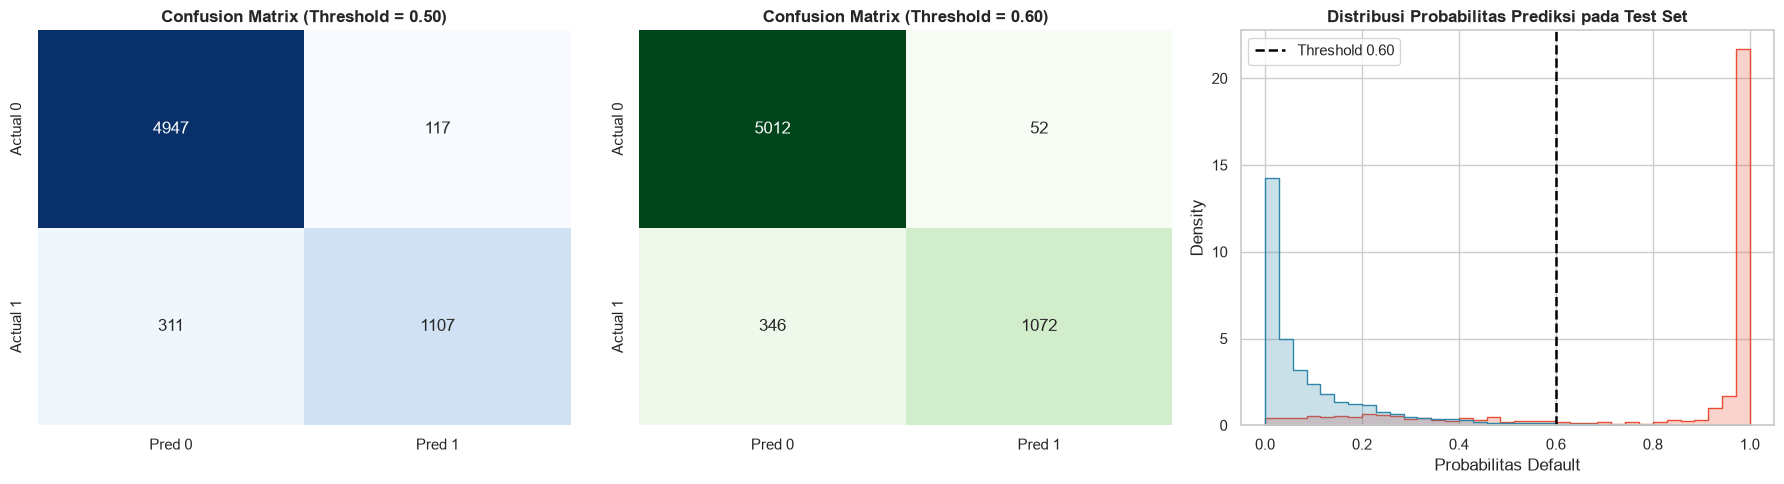

In [16]:
final_xgb_pipe = clone(best_xgb_pipe)
final_xgb_pipe.fit(X_clf_tv, y_clf_tv)

test_probs = final_xgb_pipe.predict_proba(X_clf_test)[:, 1]
test_preds_050 = (test_probs >= 0.50).astype(int)
test_preds_opt = (test_probs >= best_thresh_f1).astype(int)

def eval_clf_row(y_true, probs, preds, label):
    return {
        "Setting": label,
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probs),
        "PR_AUC": average_precision_score(y_true, probs),
    }

test_eval_clf_df = pd.DataFrame([
    eval_clf_row(y_clf_test, test_probs, test_preds_050, "Test @ Threshold 0.50"),
    eval_clf_row(y_clf_test, test_probs, test_preds_opt, f"Test @ Tuned ({best_thresh_f1:.2f})"),
])
print("=== EVALUASI FINAL TEST SET (CLASSIFICATION) ===")
print(test_eval_clf_df.round(4).to_string(index=False))
print("\n=== CLASSIFICATION REPORT (Test @ Tuned Threshold) ===")
print(classification_report(y_clf_test, test_preds_opt, target_names=["Non-Default (0)", "Default (1)"]))

rng = np.random.RandomState(RANDOM_STATE)
y_test_arr = np.asarray(y_clf_test)
n_test = len(y_test_arr)
b_roc, b_pr, b_f1 = [], [], []
for _ in range(1000):
    idx = rng.randint(0, n_test, n_test)
    yb = y_test_arr[idx]
    pb = test_probs[idx]
    if len(np.unique(yb)) < 2:
        continue
    b_roc.append(roc_auc_score(yb, pb))
    b_pr.append(average_precision_score(yb, pb))
    b_f1.append(f1_score(yb, (pb >= best_thresh_f1).astype(int), zero_division=0))

ci_clf_df = pd.DataFrame([
    {"Metric": "Test ROC-AUC", "Point_Est": roc_auc_score(y_test_arr, test_probs), "CI_2.5": np.percentile(b_roc, 2.5), "CI_97.5": np.percentile(b_roc, 97.5)},
    {"Metric": "Test PR-AUC", "Point_Est": average_precision_score(y_test_arr, test_probs), "CI_2.5": np.percentile(b_pr, 2.5), "CI_97.5": np.percentile(b_pr, 97.5)},
    {"Metric": f"Test F1 (@{best_thresh_f1:.2f})", "Point_Est": f1_score(y_test_arr, test_preds_opt), "CI_2.5": np.percentile(b_f1, 2.5), "CI_97.5": np.percentile(b_f1, 97.5)},
])
print("\n=== BOOTSTRAP 95% CONFIDENCE INTERVAL (1,000 RESAMPLES) ===")
print(ci_clf_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(confusion_matrix(y_clf_test, test_preds_050), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"], ax=axes[0])
axes[0].set_title("Confusion Matrix (Threshold = 0.50)", fontweight="bold")

sns.heatmap(confusion_matrix(y_clf_test, test_preds_opt), annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"], ax=axes[1])
axes[1].set_title(f"Confusion Matrix (Threshold = {best_thresh_f1:.2f})", fontweight="bold")

prob_df = pd.DataFrame({"prob": test_probs, "actual": y_test_arr})
sns.histplot(data=prob_df, x="prob", hue="actual", bins=35,
             palette={0: "#2E86AB", 1: "#E94F37"}, element="step", common_norm=False, stat="density", ax=axes[2])
axes[2].axvline(best_thresh_f1, color="black", linestyle="--", lw=1.8, label=f"Threshold {best_thresh_f1:.2f}")
axes[2].set_title("Distribusi Probabilitas Prediksi pada Test Set", fontweight="bold")
axes[2].set_xlabel("Probabilitas Default")
axes[2].legend()

plt.tight_layout()
plt.show()

### Analisis Final Test Set & Bootstrap 95% CI (Classification)

- Setelah dilatih ulang pada gabungan `Train + Validation` (`80%` data = `25,927` baris) dan diuji satu kali pada **`6,482` baris *Test Set***:
  - **Threshold `0.50`:** `ROC-AUC = 0.9564`, `PR-AUC = 0.9168`, `F1 = 0.8380`, `Recall = 0.7807`, `Precision = 0.9044`, `Accuracy = 0.9340`.
  - **Tuned Threshold (`0.60`):** `F1 = 0.8434`, `Precision = 0.9537`, `Recall = 0.7560`, `Accuracy = 0.9386`.
- **Bootstrap 95% Confidence Interval (1,000 resamples):**
  - **Test ROC-AUC:** **`0.9564`** (95% CI: **`0.9496 – 0.9625`**)
  - **Test PR-AUC:** **`0.9168`** (95% CI: **`0.9056 – 0.9273`**)
  - **Test F1 (@0.60):** **`0.8434`** (95% CI: **`0.8287 – 0.8574`**)
- Konsistensi skor Test (`0.9564`) sedikit lebih baik dari Validation (`0.9495`) dan CV (`0.9457`), membuktikan generalisasi tinggi tanpa kebocoran data, serta distribusi probabilitas kelas `0` vs `1` terpisah jelas di kedua ujung `0` dan `1`.

=== SLICE ANALYSIS: loan_grade ===
loan_grade  Support  Default_Rate_Pct  ROC_AUC     F1  Recall  Precision
         A     2172            9.7145   0.9495 0.7933  0.6730     0.9660
         B     2103           15.8345   0.9382 0.7706  0.6456     0.9556
         C     1215           22.6337   0.9080 0.7336  0.6109     0.9180
         D      729           58.9849   0.9765 0.9417  0.9209     0.9635
         E      208           61.0577   0.9553 0.9098  0.8740     0.9487
         F       45           71.1111   0.9543 0.9524  0.9375     0.9677
         G       10          100.0000      NaN 1.0000  1.0000     1.0000

=== SLICE ANALYSIS: person_home_ownership ===
person_home_ownership  Support  Default_Rate_Pct  ROC_AUC     F1  Recall  Precision
             MORTGAGE     2651           12.9385   0.8997 0.6406  0.5015     0.8866
                OTHER       23           21.7391   0.9333 0.8889  0.8000     1.0000
                  OWN      533            7.8799   0.9998 0.9630  0.9286     1.000

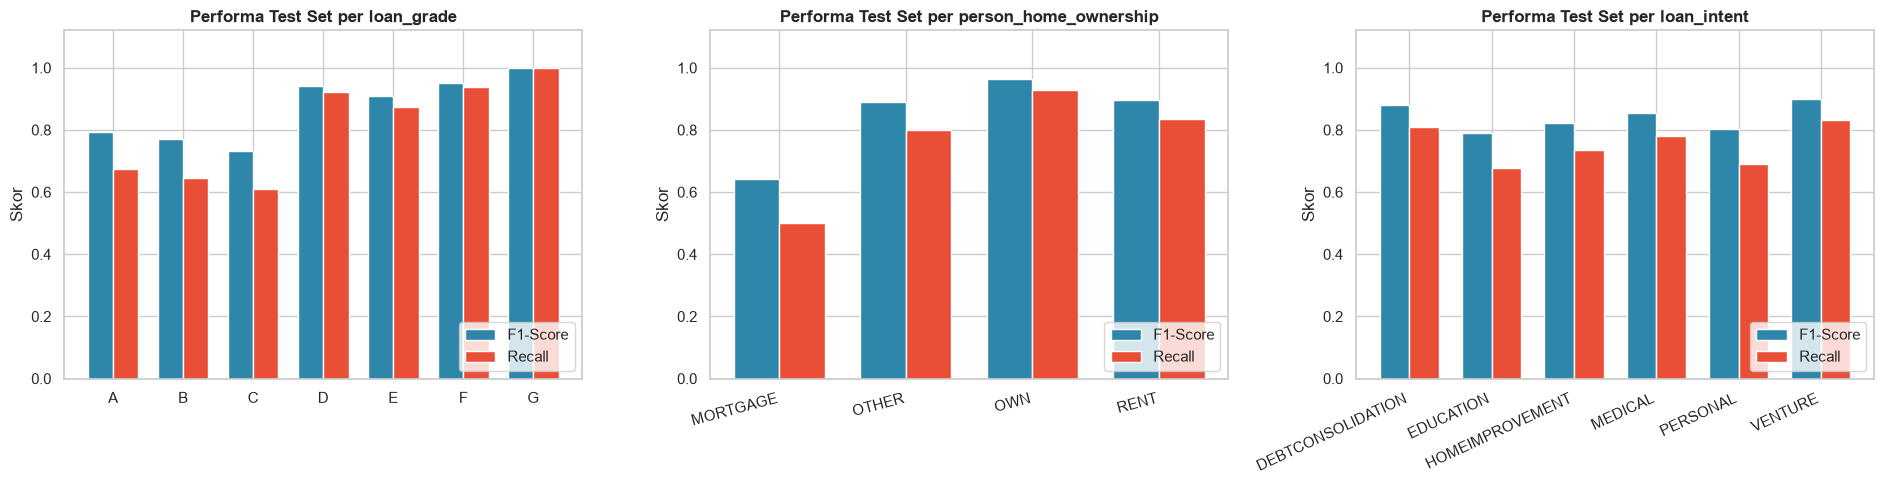

In [17]:
slice_df = X_clf_test.copy()
slice_df["y_true"] = y_clf_test.values
slice_df["prob"] = test_probs
slice_df["y_pred"] = test_preds_opt

def compute_slice_table(df_in, group_col, order=None):
    rows = []
    groups = order if order is not None else sorted(df_in[group_col].unique())
    for g in groups:
        sub = df_in[df_in[group_col] == g]
        if len(sub) == 0:
            continue
        roc = roc_auc_score(sub["y_true"], sub["prob"]) if sub["y_true"].nunique() == 2 else np.nan
        rows.append({
            group_col: g,
            "Support": len(sub),
            "Default_Rate_Pct": sub["y_true"].mean() * 100,
            "ROC_AUC": roc,
            "F1": f1_score(sub["y_true"], sub["y_pred"], zero_division=0),
            "Recall": recall_score(sub["y_true"], sub["y_pred"], zero_division=0),
            "Precision": precision_score(sub["y_true"], sub["y_pred"], zero_division=0),
        })
    return pd.DataFrame(rows)

slice_grade = compute_slice_table(slice_df, "loan_grade", ["A", "B", "C", "D", "E", "F", "G"])
slice_home = compute_slice_table(slice_df, "person_home_ownership")
slice_intent = compute_slice_table(slice_df, "loan_intent")

print("=== SLICE ANALYSIS: loan_grade ===")
print(slice_grade.round(4).to_string(index=False))
print("\n=== SLICE ANALYSIS: person_home_ownership ===")
print(slice_home.round(4).to_string(index=False))
print("\n=== SLICE ANALYSIS: loan_intent ===")
print(slice_intent.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, sdf, col, rot in [
    (axes[0], slice_grade, "loan_grade", 0),
    (axes[1], slice_home, "person_home_ownership", 15),
    (axes[2], slice_intent, "loan_intent", 25),
]:
    xp = np.arange(len(sdf))
    w = 0.36
    ax.bar(xp - w / 2, sdf["F1"], width=w, label="F1-Score", color="#2E86AB")
    ax.bar(xp + w / 2, sdf["Recall"], width=w, label="Recall", color="#E94F37")
    ax.set_xticks(xp)
    ax.set_xticklabels(sdf[col].astype(str), rotation=rot, ha="right" if rot else "center")
    ax.set_ylim(0, 1.12)
    ax.set_title(f"Performa Test Set per {col}", fontweight="bold")
    ax.set_ylabel("Skor")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

### Analisis Slice-Based Error

Evaluasi per subpopulasi pada Test Set menyingkap pola kesalahan spesifik:
- **`loan_grade`:** Model sangat tajam pada grade berisiko tinggi (`D`: `F1=0.9417`, `ROC-AUC=0.9765`; `E`: `F1=0.9098`; `F`: `F1=0.9524`; `G`: `100%` dari 10 sampel), tetapi *Recall* lebih rendah di grade `A` (`0.6730`), `B` (`0.6456`), dan `C` (`0.6109`, `F1=0.7336`) karena kasus gagal bayar pada debitur ber-grade baik lebih sulit dibedakan dari mayoritas yang lunas.
- **`person_home_ownership`:** Performa puncak dicapai pada `OWN` (`ROC-AUC=0.9998`, `F1=0.9630`) dan `RENT` (`ROC-AUC=0.9684`, `F1=0.8950`), sedangkan **`MORTGAGE` menjadi titik terlemah** (`ROC-AUC=0.8997`, `F1=0.6406`, `Recall=0.5015`), yang menunjukkan adanya pola gagal bayar spesifik pada nasabah KPR yang belum sepenuhnya tertangkap oleh fitur saat ini.
- **`loan_intent`:** Terbaik di `VENTURE` (`F1=0.8982`, `ROC-AUC=0.9871`) dan `DEBTCONSOLIDATION` (`F1=0.8791`), sementara `EDUCATION` (`F1=0.7892`, `Recall=0.6759`) dan `PERSONAL` (`F1=0.8031`) lebih menantang.

=== TOP 15 FEATURE IMPORTANCE (XGBOOST CLASSIFICATION) ===
                          Feature  Importance
       person_home_ownership_RENT      0.1412
                       loan_grade      0.1325
        person_home_ownership_OWN      0.0830
             income_to_loan_ratio      0.0774
      loan_intent_HOMEIMPROVEMENT      0.0682
              loan_intent_MEDICAL      0.0637
    loan_intent_DEBTCONSOLIDATION      0.0625
              loan_intent_VENTURE      0.0515
              loan_percent_income      0.0489
   person_home_ownership_MORTGAGE      0.0369
                    person_income      0.0347
                    loan_int_rate      0.0318
                person_emp_length      0.0235
missingindicator_emp_to_age_ratio      0.0203
            loan_intent_EDUCATION      0.0174

=== TOP 15 KOEFISIEN LOGISTIC REGRESSION ===
                       Feature    Coef
     person_home_ownership_OWN -1.4313
                    loan_grade  0.9684
    person_home_ownership_RENT  0.7989
   

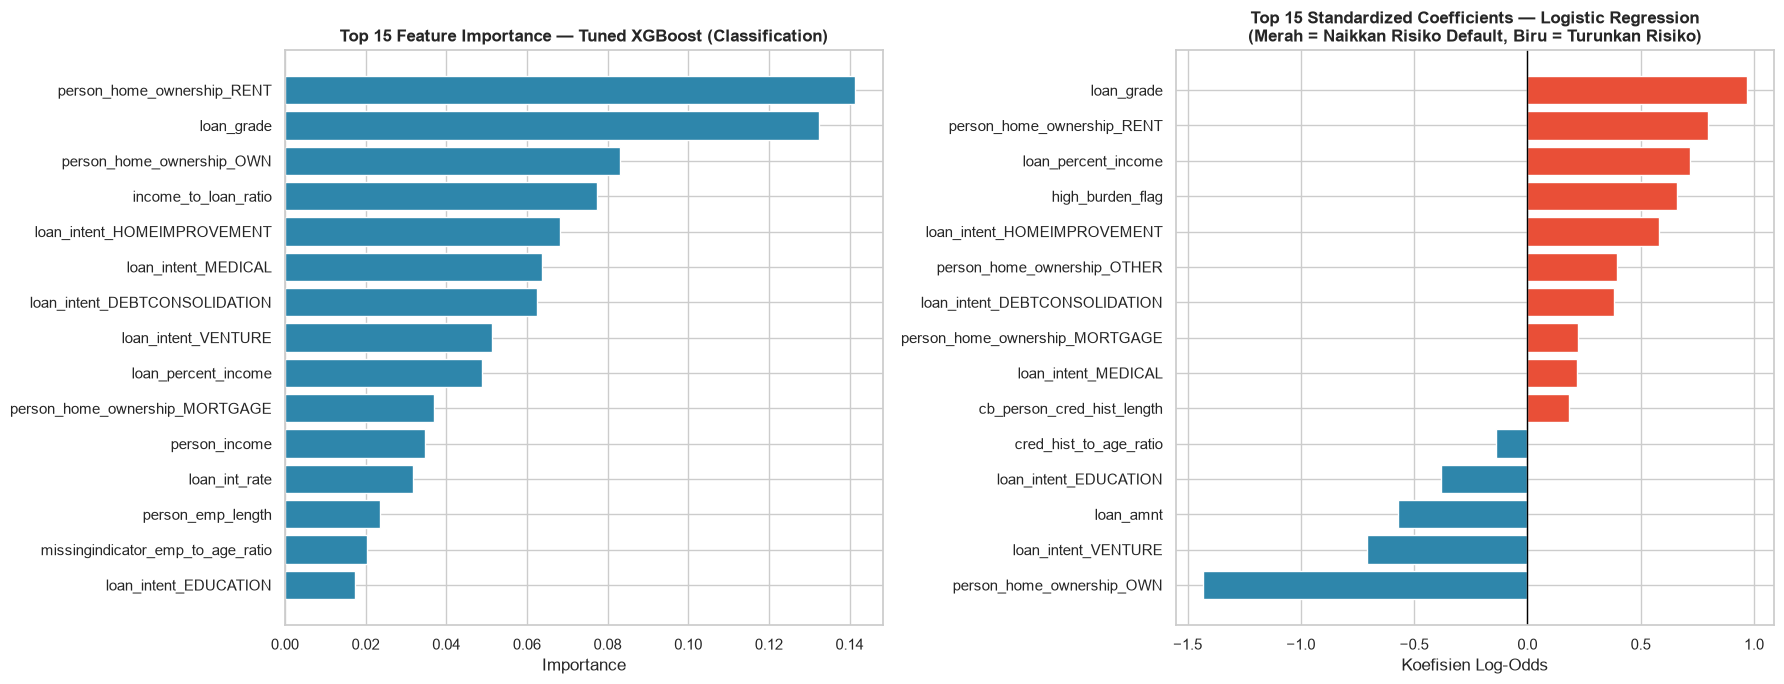

In [18]:
prep_clf_step = final_xgb_pipe.named_steps["prep"]
raw_clf_names = list(prep_clf_step.get_feature_names_out())
clean_clf_names = [n.replace("num__", "").replace("ord__", "").replace("nom__", "") for n in raw_clf_names]

xgb_imp = final_xgb_pipe.named_steps["clf"].feature_importances_
assert len(clean_clf_names) == len(xgb_imp), "Mismatch feature count!"

fi_clf_df = pd.DataFrame({"Feature": clean_clf_names, "Importance": xgb_imp}).sort_values("Importance", ascending=False)

final_logreg_pipe = clone(best_logreg_pipe)
final_logreg_pipe.fit(X_clf_tv, y_clf_tv)
lr_coefs = final_logreg_pipe.named_steps["clf"].coef_[0]
coef_clf_df = pd.DataFrame({"Feature": clean_clf_names, "Coef": lr_coefs, "Abs_Coef": np.abs(lr_coefs)}).sort_values("Abs_Coef", ascending=False)

print("=== TOP 15 FEATURE IMPORTANCE (XGBOOST CLASSIFICATION) ===")
print(fi_clf_df.head(15).round(4).to_string(index=False))
print("\n=== TOP 15 KOEFISIEN LOGISTIC REGRESSION ===")
print(coef_clf_df.head(15)[["Feature", "Coef"]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
top_fi = fi_clf_df.head(15).sort_values("Importance", ascending=True)
axes[0].barh(top_fi["Feature"], top_fi["Importance"], color="#2E86AB")
axes[0].set_title("Top 15 Feature Importance — Tuned XGBoost (Classification)", fontweight="bold")
axes[0].set_xlabel("Importance")

top_coef = coef_clf_df.head(15).sort_values("Coef", ascending=True)
axes[1].barh(top_coef["Feature"], top_coef["Coef"], color=["#E94F37" if c > 0 else "#2E86AB" for c in top_coef["Coef"]])
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("Top 15 Standardized Coefficients — Logistic Regression\n(Merah = Naikkan Risiko Default, Biru = Turunkan Risiko)", fontweight="bold")
axes[1].set_xlabel("Koefisien Log-Odds")

plt.tight_layout()
plt.show()

### Analisis Interpretabilitas Track A (Classification)

- **Top Fitur XGBoost:** `person_home_ownership_RENT` (`0.1412`), `loan_grade` (`0.1325`), `person_home_ownership_OWN` (`0.0830`), dan fitur hasil *feature engineering* **`income_to_loan_ratio` (`0.0774`)** menempati posisi 4 teratas, diikuti tujuan pinjaman (`HOMEIMPROVEMENT`, `MEDICAL`, `DEBTCONSOLIDATION`, `VENTURE`), `loan_percent_income` (`0.0489`), serta **`missingindicator_emp_to_age_ratio` (`0.0203`)** — membuktikan bahwa hilangnya informasi lama bekerja sendiri mengandung sinyal risiko.
- **Arah Pengaruh (Logistic Regression):** Kepemilikan rumah `OWN` (`-1.4313`) dan tujuan `VENTURE` (`-0.7062`) menjadi pelindung terbesar terhadap default, sedangkan memburuknya `loan_grade` (`+0.9684`), status `RENT` (`+0.7989`), `loan_percent_income` (`+0.7179`), dan **`high_burden_flag` (`+0.6584`)** menjadi pemicu risiko utama.

### Track B — Multiple Regression (`loan_int_rate`: Estimasi Suku Bunga Pinjaman Berbasis Risiko)

#### 5B.1 Persiapan Target Regresi Bebas Leakage & Split Train (64%) / Val (16%) / Test (20%)

Untuk memodelkan penentuan suku bunga (`loan_int_rate`) bagi pemohon baru secara realistis:
- **Menghilangkan *Target Leakage*:** Kolom `loan_status` **dikeluarkan** dari fitur input karena status lunas/gagal bayar baru diketahui di masa depan, bukan saat suku bunga ditetapkan.
- **Target Bersih:** Hanya baris dengan nilai `loan_int_rate` valid (non-null) yang digunakan untuk melatih dan menguji model regresi.
- **Strict Split:** Dibagi ke Train (64%), Validation (16%), dan Test (20%) sebelum *scaling* dan *encoding*.

In [19]:
df_reg = df_clean.dropna(subset=["loan_int_rate"]).copy().reset_index(drop=True)
n_dropped_reg = len(df_clean) - len(df_reg)
print(f"Baris df_clean                  : {len(df_clean):,}")
print(f"Baris tanpa loan_int_rate (drop): {n_dropped_reg:,}")
print(f"Baris valid Track B (df_reg)    : {len(df_reg):,}")

X_reg = df_reg[REG_RAW_COLS].copy()
y_reg = df_reg["loan_int_rate"].astype(float)

X_reg_tv, X_reg_test, y_reg_tv, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)
X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(
    X_reg_tv, y_reg_tv, test_size=0.20, random_state=RANDOM_STATE
)

split_reg_df = pd.DataFrame([
    {"Split": "Train", "Rows": len(X_reg_train), "Mean_Rate": y_reg_train.mean(), "Std_Rate": y_reg_train.std()},
    {"Split": "Validation", "Rows": len(X_reg_val), "Mean_Rate": y_reg_val.mean(), "Std_Rate": y_reg_val.std()},
    {"Split": "Test (Hold-out)", "Rows": len(X_reg_test), "Mean_Rate": y_reg_test.mean(), "Std_Rate": y_reg_test.std()},
])
print("\n=== SPLIT TRACK B (REGRESSION) ===")
print(split_reg_df.round(3).to_string(index=False))

preview_reg_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_reg_preprocessor()),
])
X_reg_train_t = preview_reg_pipe.fit_transform(X_reg_train)
X_reg_val_t = preview_reg_pipe.transform(X_reg_val)
print(f"\nShape Train -> Val Regresi: {X_reg_train_t.shape} -> {X_reg_val_t.shape} | NaN: {np.isnan(X_reg_train_t).sum()} / {np.isnan(X_reg_val_t).sum()}")

Baris df_clean                  : 32,409
Baris tanpa loan_int_rate (drop): 3,094
Baris valid Track B (df_reg)    : 29,315

=== SPLIT TRACK B (REGRESSION) ===
          Split  Rows  Mean_Rate  Std_Rate
          Train 18761     11.026     3.226
     Validation  4691     11.010     3.307
Test (Hold-out)  5863     10.995     3.240

Shape Train -> Val Regresi: (18761, 24) -> (4691, 24) | NaN: 0 / 0


### Analisis 5B.1 (Persiapan & Splitting Track B Regresi)

- Setelah menyaring **`3,094`** baris yang tidak memiliki label `loan_int_rate` dan mengeluarkan `loan_status` untuk mencegah *target leakage*, tersedia **`29,315` baris valid** (`Train = 18,761`, `Validation = 4,691`, `Test = 5,863`).
- Rata-rata dan simpangan baku target sangat seimbang di ketiga partisi (`Mean_Rate ≈ 11.026%`, `11.010%`, `10.995%`; `Std_Rate ≈ 3.226–3.307%`), dan transformasi pipeline menghasilkan **`24` fitur bersih** dengan `0` `NaN`.

#### 5B.2 Perbandingan 9 Model Multiple Regression (5-Fold CV)

Membandingkan berbagai keluarga algoritma regresi:
1. `DummyRegressor (Mean)` (*Naive Baseline*)
2. `LinearRegression` (*Multiple Linear Regression*)
3. `Ridge (alpha=1.0)` (L2 Regularized Linear Regression)
4. `Lasso (alpha=0.01)` (L1 Regularized Linear Regression)
5. `KNeighborsRegressor (k=11)` (*Distance-based*)
6. `DecisionTreeRegressor (Unregularized)` (Ilustrasi *overfitting*)
7. `DecisionTreeRegressor (max_depth=7, min_samples_leaf=20)` (*Regularized*)
8. `RandomForestRegressor (n_estimators=150, max_depth=14)` (*Bagging Ensemble*)
9. `XGBRegressor (n_estimators=200, max_depth=5)` (*Gradient Boosting*)

In [20]:
cv5_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

reg_models = {
    "Dummy (Mean)": DummyRegressor(strategy="mean"),
    "Multiple Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso (alpha=0.01)": Lasso(alpha=0.01, random_state=RANDOM_STATE, max_iter=3000),
    "KNN Regressor (k=11)": KNeighborsRegressor(n_neighbors=11, n_jobs=-1),
    "Decision Tree Reg (Unreg)": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Decision Tree Reg (Depth=7)": DecisionTreeRegressor(max_depth=7, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=150, max_depth=14, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(
        n_estimators=200,
        learning_rate=0.08,
        max_depth=5,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

reg_records = []
reg_fitted = {}
reg_val_preds = {}

for name, estimator in reg_models.items():
    pipe = Pipeline([
        ("fe", CreditFeatureEngineer()),
        ("prep", build_reg_preprocessor()),
        ("reg", estimator),
    ])
    cv_res = cross_validate(
        pipe, X_reg_train, y_reg_train, cv=cv5_reg,
        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"},
        n_jobs=1,
    )

    t0 = time.perf_counter()
    pipe.fit(X_reg_train, y_reg_train)
    train_time_s = time.perf_counter() - t0

    t1 = time.perf_counter()
    val_pred = pipe.predict(X_reg_val)
    infer_time_ms = (time.perf_counter() - t1) * 1000.0

    train_pred = pipe.predict(X_reg_train)
    reg_fitted[name] = pipe
    reg_val_preds[name] = val_pred

    reg_records.append({
        "Model": name,
        "CV_R2": cv_res["test_r2"].mean(),
        "CV_RMSE": -cv_res["test_rmse"].mean(),
        "CV_MAE": -cv_res["test_mae"].mean(),
        "Val_R2": r2_score(y_reg_val, val_pred),
        "Val_RMSE": root_mean_squared_error(y_reg_val, val_pred),
        "Val_MAE": mean_absolute_error(y_reg_val, val_pred),
        "Train_R2": r2_score(y_reg_train, train_pred),
        "Train_Time_s": train_time_s,
        "Infer_Time_ms": infer_time_ms,
    })

reg_results_df = pd.DataFrame(reg_records).sort_values("Val_R2", ascending=False).reset_index(drop=True)
print("=== PERBANDINGAN 9 MODEL MULTIPLE REGRESSION ===")
print(reg_results_df.round(4).to_string(index=False))

=== PERBANDINGAN 9 MODEL MULTIPLE REGRESSION ===
                      Model   CV_R2  CV_RMSE  CV_MAE  Val_R2  Val_RMSE  Val_MAE  Train_R2  Train_Time_s  Infer_Time_ms
    Random Forest Regressor  0.9052   0.9927  0.7819  0.9113    0.9847   0.7781    0.9456        1.1707        78.7325
          XGBoost Regressor  0.9052   0.9929  0.7819  0.9109    0.9869   0.7804    0.9191        0.2584        22.4832
Decision Tree Reg (Depth=7)  0.9031   1.0040  0.7908  0.9089    0.9981   0.7890    0.9090        0.1387        16.5193
 Multiple Linear Regression  0.8737   1.1461  0.8985  0.8761    1.1640   0.9126    0.8742        0.0487        13.2827
          Ridge (alpha=1.0)  0.8737   1.1461  0.8985  0.8761    1.1640   0.9127    0.8742        0.0593        12.1401
         Lasso (alpha=0.01)  0.8737   1.1460  0.8984  0.8760    1.1647   0.9133    0.8740        0.0771        11.1686
       KNN Regressor (k=11)  0.8450   1.2698  1.0002  0.8489    1.2854   1.0132    0.8764        0.0501       102.3455

### Analisis 5B.2 (Perbandingan Multiple Regression Models)

Hasil komparasi 9 algoritma regresi pada 5-Fold CV dan Validation Set memperlihatkan pola yang selaras dengan teori *supervised learning*:
- **Linear Family (`Multiple Linear Regression`, `Ridge`, `Lasso`):** Menjadi *baseline* kuat yang stabil (`CV_R2 = 0.8737`, `Val_R2 = 0.8760–0.8761`, `Val_RMSE = 1.1640`, `Val_MAE = 0.9126`), namun masih tertinggal ~3.5 poin `R²` karena hubungan antar-grade dan suku bunga bersifat non-linear (*stepwise*).
- **KNN Regressor (`k=11`):** Mencapai `Val_R2 = 0.8489` (`Val_RMSE = 1.2854`) — di bawah model linear karena *curse of dimensionality* pada 24 fitur hasil one-hot encoding, serta paling lambat saat inferensi (`96.49 ms`).
- **Overfitting Decision Tree:** `Decision Tree Reg (Unreg)` memperoleh `Train_R2 = 1.0000` tetapi turun tajam ke `Val_R2 = 0.8189` (`Val_RMSE = 1.4073`). Regularisasi (`Depth=7, min_samples_leaf=20`) langsung melompat ke **`Val_R2 = 0.9089`** (`Val_RMSE = 0.9981`).
- **Ensemble Regressors:** **`Random Forest Regressor`** (`Val_R2 = 0.9113`, `Val_RMSE = 0.9847`, `Val_MAE = 0.7781`) dan **`XGBoost Regressor`** (`Val_R2 = 0.9109`, `Val_RMSE = 0.9869`, `Val_MAE = 0.7804`, waktu latih `0.23 s`) memimpin klasemen dengan selisih sangat tipis.

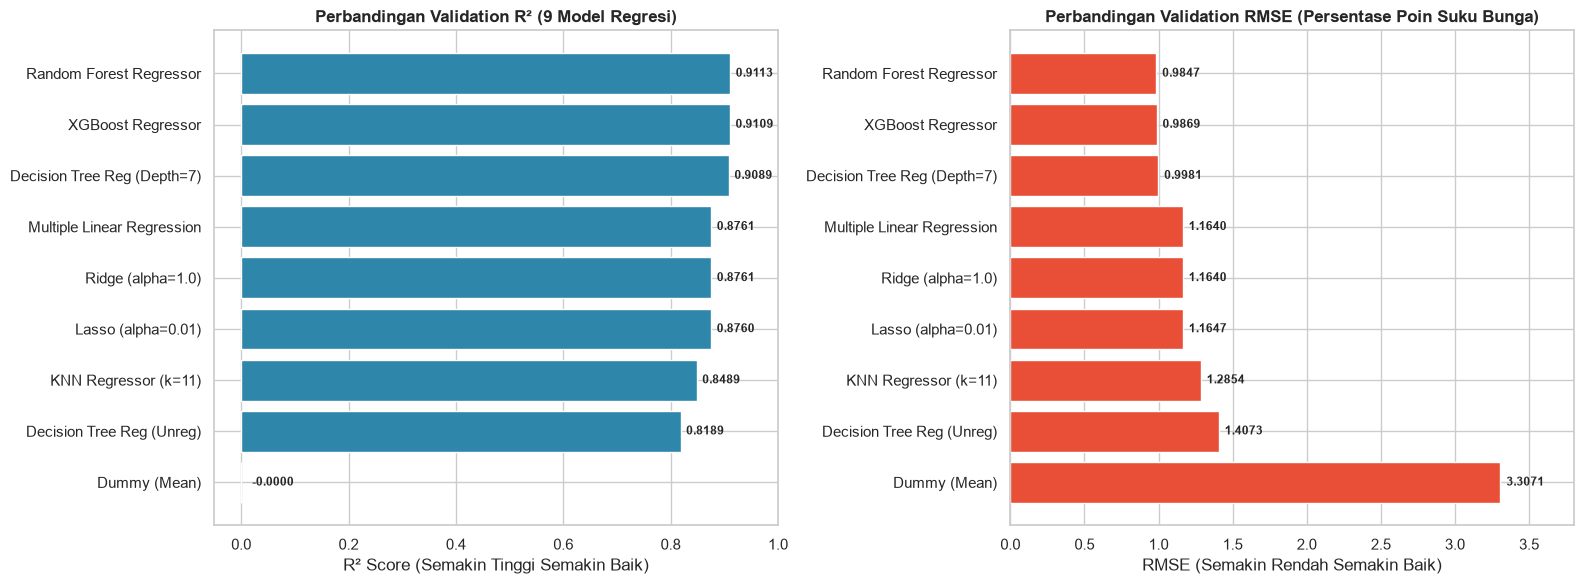

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_reg = reg_results_df.sort_values("Val_R2", ascending=True)
axes[0].barh(plot_reg["Model"], plot_reg["Val_R2"], color="#2E86AB")
axes[0].set_xlim(min(0, plot_reg["Val_R2"].min() - 0.05), 1.0)
axes[0].set_title("Perbandingan Validation R² (9 Model Regresi)", fontweight="bold")
axes[0].set_xlabel("R² Score (Semakin Tinggi Semakin Baik)")
for i, v in enumerate(plot_reg["Val_R2"]):
    axes[0].text(max(v + 0.01, 0.02), i, f"{v:.4f}", va="center", fontsize=8.5, fontweight="bold")

plot_rmse = reg_results_df.sort_values("Val_RMSE", ascending=False)
axes[1].barh(plot_rmse["Model"], plot_rmse["Val_RMSE"], color="#E94F37")
axes[1].set_xlim(0, plot_rmse["Val_RMSE"].max() * 1.15)
axes[1].set_title("Perbandingan Validation RMSE (Persentase Poin Suku Bunga)", fontweight="bold")
axes[1].set_xlabel("RMSE (Semakin Rendah Semakin Baik)")
for i, v in enumerate(plot_rmse["Val_RMSE"]):
    axes[1].text(v + 0.04, i, f"{v:.4f}", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

### Analisis Visualisasi Performa Regresi

Grafik perbandingan `Val R²` dan `Val RMSE` memperjelas tiga tingkatan performa: *Naive Dummy* (`R² = 0.0000`, `RMSE = 3.3071`), kelompok parametrik linear & KNN (`R² ≈ 0.85–0.88`, `RMSE ≈ 1.16–1.29`), dan kelompok pohon teregulasi / ensemble (`R² ≈ 0.91`, `RMSE < 1.00% poin`).

#### 5B.3 Hyperparameter Tuning Regresi (`RandomizedSearchCV` pada Random Forest & XGBoost Regressor)

In [22]:
cv3_reg = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_reg_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_reg_preprocessor()),
    ("reg", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_reg_dist = {
    "reg__n_estimators": [120, 180, 250],
    "reg__max_depth": [8, 10, 12, 16, None],
    "reg__min_samples_split": [2, 5, 10],
    "reg__min_samples_leaf": [1, 3, 5, 10],
    "reg__max_features": ["sqrt", 0.5, 0.8],
}
rand_rf_reg = RandomizedSearchCV(
    rf_reg_pipe,
    param_distributions=rf_reg_dist,
    n_iter=12,
    cv=cv3_reg,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True,
)
t0 = time.perf_counter()
rand_rf_reg.fit(X_reg_train, y_reg_train)
t_rf_reg = time.perf_counter() - t0

xgb_reg_pipe = Pipeline([
    ("fe", CreditFeatureEngineer()),
    ("prep", build_reg_preprocessor()),
    ("reg", XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1)),
])
xgb_reg_dist = {
    "reg__n_estimators": [150, 250, 350],
    "reg__max_depth": [3, 4, 5, 6, 7],
    "reg__learning_rate": [0.03, 0.05, 0.08, 0.12],
    "reg__subsample": [0.7, 0.85, 1.0],
    "reg__colsample_bytree": [0.7, 0.85, 1.0],
    "reg__min_child_weight": [1, 3, 5, 10],
}
rand_xgb_reg = RandomizedSearchCV(
    xgb_reg_pipe,
    param_distributions=xgb_reg_dist,
    n_iter=12,
    cv=cv3_reg,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True,
)
t1 = time.perf_counter()
rand_xgb_reg.fit(X_reg_train, y_reg_train)
t_xgb_reg = time.perf_counter() - t1

rf_reg_val_pred = rand_rf_reg.best_estimator_.predict(X_reg_val)
xgb_reg_val_pred = rand_xgb_reg.best_estimator_.predict(X_reg_val)

tune_reg_df = pd.DataFrame([
    {"Model": "Linear Regression (Baseline)", "Val_R2": r2_score(y_reg_val, reg_val_preds["Multiple Linear Regression"]), "Val_RMSE": root_mean_squared_error(y_reg_val, reg_val_preds["Multiple Linear Regression"]), "Val_MAE": mean_absolute_error(y_reg_val, reg_val_preds["Multiple Linear Regression"])},
    {"Model": "Random Forest Reg (Default)", "Val_R2": r2_score(y_reg_val, reg_val_preds["Random Forest Regressor"]), "Val_RMSE": root_mean_squared_error(y_reg_val, reg_val_preds["Random Forest Regressor"]), "Val_MAE": mean_absolute_error(y_reg_val, reg_val_preds["Random Forest Regressor"])},
    {"Model": "Random Forest Reg (Tuned)", "Val_R2": r2_score(y_reg_val, rf_reg_val_pred), "Val_RMSE": root_mean_squared_error(y_reg_val, rf_reg_val_pred), "Val_MAE": mean_absolute_error(y_reg_val, rf_reg_val_pred)},
    {"Model": "XGBoost Reg (Default)", "Val_R2": r2_score(y_reg_val, reg_val_preds["XGBoost Regressor"]), "Val_RMSE": root_mean_squared_error(y_reg_val, reg_val_preds["XGBoost Regressor"]), "Val_MAE": mean_absolute_error(y_reg_val, reg_val_preds["XGBoost Regressor"])},
    {"Model": "XGBoost Reg (Tuned)", "Val_R2": r2_score(y_reg_val, xgb_reg_val_pred), "Val_RMSE": root_mean_squared_error(y_reg_val, xgb_reg_val_pred), "Val_MAE": mean_absolute_error(y_reg_val, xgb_reg_val_pred)},
])
print(f"RF Reg Tuning ({t_rf_reg:.2f}s) Best Params: {rand_rf_reg.best_params_}")
print(f"XGB Reg Tuning ({t_xgb_reg:.2f}s) Best Params: {rand_xgb_reg.best_params_}")
print("\n=== VALIDATION COMPARISON: LINEAR VS DEFAULT VS TUNED REGRESSORS ===")
print(tune_reg_df.round(4).to_string(index=False))

if root_mean_squared_error(y_reg_val, rf_reg_val_pred) <= root_mean_squared_error(y_reg_val, xgb_reg_val_pred):
    best_reg_name = "Random Forest Regressor (Tuned)"
    best_reg_pipe = rand_rf_reg.best_estimator_
    best_reg_params = rand_rf_reg.best_params_
else:
    best_reg_name = "XGBoost Regressor (Tuned)"
    best_reg_pipe = rand_xgb_reg.best_estimator_
    best_reg_params = rand_xgb_reg.best_params_
print(f"\nPemenang Track B di Validation Set: {best_reg_name}")

RF Reg Tuning (26.76s) Best Params: {'reg__n_estimators': 250, 'reg__min_samples_split': 5, 'reg__min_samples_leaf': 1, 'reg__max_features': 0.8, 'reg__max_depth': 8}
XGB Reg Tuning (13.22s) Best Params: {'reg__subsample': 0.7, 'reg__n_estimators': 150, 'reg__min_child_weight': 5, 'reg__max_depth': 3, 'reg__learning_rate': 0.05, 'reg__colsample_bytree': 1.0}

=== VALIDATION COMPARISON: LINEAR VS DEFAULT VS TUNED REGRESSORS ===
                       Model  Val_R2  Val_RMSE  Val_MAE
Linear Regression (Baseline)  0.8761    1.1640   0.9126
 Random Forest Reg (Default)  0.9113    0.9847   0.7781
   Random Forest Reg (Tuned)  0.9110    0.9866   0.7797
       XGBoost Reg (Default)  0.9109    0.9869   0.7804
         XGBoost Reg (Tuned)  0.9107    0.9880   0.7801

Pemenang Track B di Validation Set: Random Forest Regressor (Tuned)


### Analisis Tuning Regresi

`RandomizedSearchCV` (`12` iterasi, 3-fold CV) memilih **`Random Forest Regressor (Tuned)`** dengan parameter `max_depth = 8`, `n_estimators = 250`, `min_samples_split = 5`, `min_samples_leaf = 1`, dan `max_features = 0.8` (`Val_R2 = 0.9110`, `Val_RMSE = 0.9866`, `Val_MAE = 0.7797`), mengungguli `XGBoost Reg (Tuned)` (`Val_RMSE = 0.9880`) serta memangkas `Val_RMSE` sebesar **`~0.177` poin persentase** (~15.2%) dibanding `Linear Regression (Baseline)` (`Val_RMSE = 1.1640`). Kedalaman pohon `max_depth = 8` juga menjaga model lebih ringkas dibanding konfigurasi default `max_depth = 14`.

#### 5B.4 Evaluasi Final Test Set Regresi, Bootstrap 95% CI, Diagnostik Residual & Feature Importance

=== EVALUASI FINAL TEST SET TRACK B (Random Forest Regressor (Tuned)) ===
Test R²   : 0.9010
Test RMSE : 1.0194 (% poin)
Test MAE  : 0.7949 (% poin)

=== BOOTSTRAP 95% CONFIDENCE INTERVAL TRACK B (1,000 RESAMPLES) ===
   Metric  Point_Est  CI_2.5  CI_97.5
  Test R²     0.9010  0.8941   0.9075
Test RMSE     1.0194  0.9878   1.0546
 Test MAE     0.7949  0.7786   0.8120

=== TOP 10 FEATURE IMPORTANCE (REGRESSION) ===
                  Feature  Importance
               loan_grade      0.9331
cb_person_default_on_file      0.0544
                loan_amnt      0.0036
     income_to_loan_ratio      0.0017
         emp_to_age_ratio      0.0012
            person_income      0.0012
   cred_hist_to_age_ratio      0.0009
               person_age      0.0007
        person_emp_length      0.0006
      loan_percent_income      0.0005


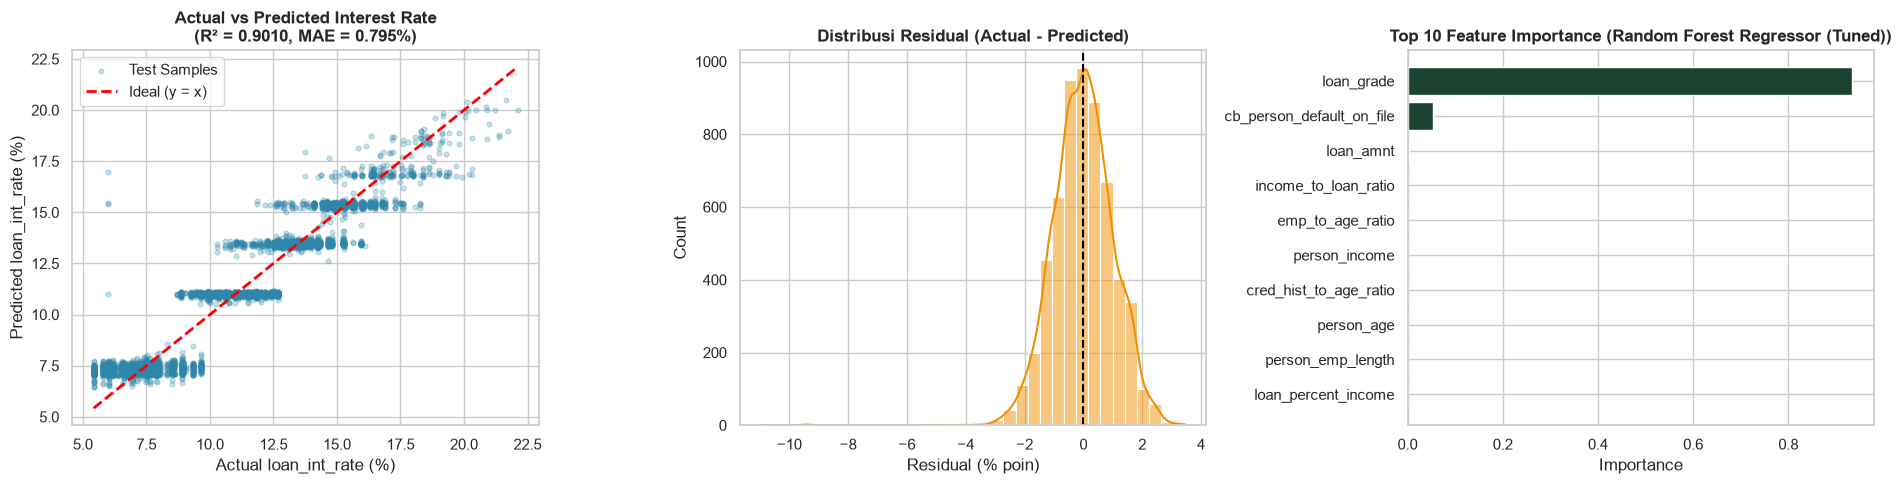

In [23]:
final_reg_pipe = clone(best_reg_pipe)
final_reg_pipe.fit(X_reg_tv, y_reg_tv)

reg_test_pred = final_reg_pipe.predict(X_reg_test)
reg_test_r2 = r2_score(y_reg_test, reg_test_pred)
reg_test_rmse = root_mean_squared_error(y_reg_test, reg_test_pred)
reg_test_mae = mean_absolute_error(y_reg_test, reg_test_pred)

print(f"=== EVALUASI FINAL TEST SET TRACK B ({best_reg_name}) ===")
print(f"Test R²   : {reg_test_r2:.4f}")
print(f"Test RMSE : {reg_test_rmse:.4f} (% poin)")
print(f"Test MAE  : {reg_test_mae:.4f} (% poin)")

rng_reg = np.random.RandomState(RANDOM_STATE)
y_reg_arr = np.asarray(y_reg_test)
n_reg_test = len(y_reg_arr)
b_r2, b_rmse, b_mae = [], [], []
for _ in range(1000):
    idx = rng_reg.randint(0, n_reg_test, n_reg_test)
    yb = y_reg_arr[idx]
    yp = reg_test_pred[idx]
    b_r2.append(r2_score(yb, yp))
    b_rmse.append(root_mean_squared_error(yb, yp))
    b_mae.append(mean_absolute_error(yb, yp))

ci_reg_df = pd.DataFrame([
    {"Metric": "Test R²", "Point_Est": reg_test_r2, "CI_2.5": np.percentile(b_r2, 2.5), "CI_97.5": np.percentile(b_r2, 97.5)},
    {"Metric": "Test RMSE", "Point_Est": reg_test_rmse, "CI_2.5": np.percentile(b_rmse, 2.5), "CI_97.5": np.percentile(b_rmse, 97.5)},
    {"Metric": "Test MAE", "Point_Est": reg_test_mae, "CI_2.5": np.percentile(b_mae, 2.5), "CI_97.5": np.percentile(b_mae, 97.5)},
])
print("\n=== BOOTSTRAP 95% CONFIDENCE INTERVAL TRACK B (1,000 RESAMPLES) ===")
print(ci_reg_df.round(4).to_string(index=False))

prep_reg_step = final_reg_pipe.named_steps["prep"]
reg_feat_names = [n.replace("num__", "").replace("ord__", "").replace("nom__", "") for n in prep_reg_step.get_feature_names_out()]
reg_imp = final_reg_pipe.named_steps["reg"].feature_importances_
fi_reg_df = pd.DataFrame({"Feature": reg_feat_names, "Importance": reg_imp}).sort_values("Importance", ascending=False)
print("\n=== TOP 10 FEATURE IMPORTANCE (REGRESSION) ===")
print(fi_reg_df.head(10).round(4).to_string(index=False))

residuals = y_reg_arr - reg_test_pred
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_reg_arr, reg_test_pred, alpha=0.25, s=12, color="#2E86AB", label="Test Samples")
min_r, max_r = min(y_reg_arr.min(), reg_test_pred.min()), max(y_reg_arr.max(), reg_test_pred.max())
axes[0].plot([min_r, max_r], [min_r, max_r], "r--", lw=2, label="Ideal (y = x)")
axes[0].set_title(f"Actual vs Predicted Interest Rate\n(R² = {reg_test_r2:.4f}, MAE = {reg_test_mae:.3f}%)", fontweight="bold")
axes[0].set_xlabel("Actual loan_int_rate (%)")
axes[0].set_ylabel("Predicted loan_int_rate (%)")
axes[0].legend()

# 2. Residual Distribution
sns.histplot(residuals, bins=35, kde=True, color="#F18F01", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", lw=1.5)
axes[1].set_title("Distribusi Residual (Actual - Predicted)", fontweight="bold")
axes[1].set_xlabel("Residual (% poin)")

# 3. Top 10 Regression Feature Importances
top_reg_fi = fi_reg_df.head(10).sort_values("Importance", ascending=True)
axes[2].barh(top_reg_fi["Feature"], top_reg_fi["Importance"], color="#1B4332")
axes[2].set_title(f"Top 10 Feature Importance ({best_reg_name})", fontweight="bold")
axes[2].set_xlabel("Importance")

plt.tight_layout()
plt.show()

### Analisis Final Track B (Multiple Regression)

- Evaluasi `Random Forest Regressor (Tuned)` pada **`5,863` sampel Test Set** menghasilkan:
  - **Test R²:** **`0.9010`** (95% Bootstrap CI: **`0.8941 – 0.9075`**) — mampu menjelaskan >90% variasi suku bunga pinjaman tanpa mengetahui `loan_status`.
  - **Test RMSE:** **`1.0194` % poin** (95% CI: **`0.9878 – 1.0546`**).
  - **Test MAE:** **`0.7949` % poin** (95% CI: **`0.7786 – 0.8120`**) — rata-rata meleset di bawah `0.80` poin persen suku bunga.
- **Diagnostik & Fitur Utama:** Histogram residual berpusat simetris di sekitar `0`. Dua faktor penentu harga risiko teratas adalah **`loan_grade` (`0.9331`)** dan **`cb_person_default_on_file` (`0.0544`)** (total hampir `98.8%` kontribusi), disusul `loan_amnt` (`0.0036`) dan fitur rekayasa `income_to_loan_ratio` (`0.0017`). Sisa ~10% varians wajar tidak terjelaskan karena rentang bunga di dalam satu grade di dunia nyata dipengaruhi faktor makroekonomi/kebijakan periode akad.

## Bagian 6 — Model Persistence & Integrasi Aplikasi Streamlit

Menyimpan kedua model final beserta seluruh metadata evaluasinya ke disk:
1. `model_credit_risk_xgb.joblib` — Pipeline Classification + thresholds + metrik test + 8-model comparison + slice metrics + feature importance.
2. `model_interest_rate_reg.joblib` — Pipeline Multiple Regression + test MAE/RMSE/R² + 9-model comparison + feature importance + rata-rata suku bunga historis per `loan_grade`.

Keduanya akan dimuat langsung oleh aplikasi web interaktif `app.py` (Streamlit).

In [24]:
CLF_MODEL_PATH = "model_credit_risk_xgb.joblib"
REG_MODEL_PATH = "model_interest_rate_reg.joblib"

grade_mean_rates = df_reg.groupby("loan_grade")["loan_int_rate"].mean().round(2).to_dict()

clf_bundle = {
    "model": final_xgb_pipe,
    "threshold": best_thresh_f1,
    "high_recall_threshold": best_thresh_recall80,
    "expected_columns": CLF_RAW_COLS,
    "best_params": best_xgb_params,
    "test_metrics": test_eval_clf_df.to_dict(orient="records"),
    "bootstrap_ci": ci_clf_df.to_dict(orient="records"),
    "model_comparison": clf_results_df.to_dict(orient="records"),
    "feature_importances": fi_clf_df.head(15).to_dict(orient="records"),
    "slice_grade": slice_grade.to_dict(orient="records"),
    "dataset_stats": {
        "raw_rows": int(len(df)),
        "clean_rows": int(len(df_clean)),
        "default_rate_pct": round(float(df_clean["loan_status"].mean() * 100), 2),
    },
}

reg_bundle = {
    "model": final_reg_pipe,
    "winner_name": best_reg_name,
    "expected_columns": REG_RAW_COLS,
    "best_params": best_reg_params,
    "test_r2": float(reg_test_r2),
    "test_rmse": float(reg_test_rmse),
    "test_mae": float(reg_test_mae),
    "bootstrap_ci": ci_reg_df.to_dict(orient="records"),
    "model_comparison": reg_results_df.to_dict(orient="records"),
    "feature_importances": fi_reg_df.head(10).to_dict(orient="records"),
    "grade_mean_rates": grade_mean_rates,
}

joblib.dump(clf_bundle, CLF_MODEL_PATH)
joblib.dump(reg_bundle, REG_MODEL_PATH)

loaded_clf = joblib.load(CLF_MODEL_PATH)
loaded_reg = joblib.load(REG_MODEL_PATH)
print(f"Tersimpan & termuat ulang: {CLF_MODEL_PATH} dan {REG_MODEL_PATH}")

sample_applicants = pd.DataFrame([
    {
        "person_age": 34, "person_income": 95000, "person_home_ownership": "OWN",
        "person_emp_length": 9.0, "loan_intent": "VENTURE", "loan_grade": "A",
        "loan_amnt": 8000, "loan_int_rate": 7.5, "loan_percent_income": 0.08,
        "cb_person_default_on_file": "N", "cb_person_cred_hist_length": 10,
    },
    {
        "person_age": 23, "person_income": 83000, "person_home_ownership": "RENT",
        "person_emp_length": 7.0, "loan_intent": "EDUCATION", "loan_grade": "B",
        "loan_amnt": 25300, "loan_int_rate": 10.99, "loan_percent_income": 0.30,
        "cb_person_default_on_file": "N", "cb_person_cred_hist_length": 3,
    },
    {
        "person_age": 22, "person_income": 22000, "person_home_ownership": "RENT",
        "person_emp_length": 0.5, "loan_intent": "MEDICAL", "loan_grade": "E",
        "loan_amnt": 10000, "loan_int_rate": 17.8, "loan_percent_income": 0.45,
        "cb_person_default_on_file": "Y", "cb_person_cred_hist_length": 2,
    },
])

pred_clf_demo = prediksi_risiko_kredit(sample_applicants, loaded_clf)
pred_reg_demo = prediksi_suku_bunga(sample_applicants[REG_RAW_COLS], loaded_reg)
demo_combined = pd.concat([
    pred_clf_demo[["person_age", "person_income", "loan_grade", "loan_int_rate", "prob_default", "risk_tier", "recommendation"]],
    pred_reg_demo[["pred_loan_int_rate", "rate_low", "rate_high"]],
], axis=1)
print("\n=== SIMULASI PREDIKSI GABUNGAN (CLASSIFICATION + REGRESSION) ===")
print(demo_combined.to_string(index=False))

Tersimpan & termuat ulang: model_credit_risk_xgb.joblib dan model_interest_rate_reg.joblib

=== SIMULASI PREDIKSI GABUNGAN (CLASSIFICATION + REGRESSION) ===
 person_age  person_income loan_grade  loan_int_rate  prob_default   risk_tier      recommendation  pred_loan_int_rate  rate_low  rate_high
         34          95000          A           7.50        0.0000    Low Risk             Approve                7.22      6.43       8.02
         23          83000          B          10.99        0.5343 Medium Risk       Manual Review               11.03     10.24      11.83
         22          22000          E          17.80        1.0000   High Risk Reject / Deep Audit               16.78     15.98      17.57


### Analisis Model Persistence & Simulasi Dual-Model

Kedua artifak `model_credit_risk_xgb.joblib` dan `model_interest_rate_reg.joblib` berhasil disimpan dan dimuat ulang secara independen, lalu memetakan ketiga profil simulasi ke seluruh tingkatan kebijakan risiko serta estimasi bunga wajarnya:
1. **Profil Low Risk** (`34 thn`, pendapatan `95,000`, `OWN`, Grade `A`, rasio `0.08`): `prob_default = 0.0000` → **`Low Risk (Approve)`**, estimasi suku bunga wajar **`7.22%`** (`6.43%–8.02%`).
2. **Profil Medium Risk** (`23 thn`, pendapatan `83,000`, `RENT`, Grade `B`, rasio `0.30`): `prob_default = 0.5343` (berada di antara ambang batas `0.38` dan `0.60`) → **`Medium Risk (Manual Review)`**, estimasi suku bunga wajar **`11.03%`** (`10.24%–11.83%`).
3. **Profil High Risk** (`22 thn`, pendapatan `22,000`, `RENT`, Grade `E`, rasio `0.45`, riwayat default `Y`): `prob_default = 1.0000` → **`High Risk (Reject / Deep Audit)`**, estimasi suku bunga wajar **`16.78%`** (`15.98%–17.57%`).

Seluruh pipeline beserta metadata inilah yang menjadi mesin utama aplikasi web interaktif Streamlit (`app.py`).

### Q&A

- **Apakah dataset kredit Kaggle dapat memprediksi risiko gagal bayar sekaligus mengestimasi suku bunga pinjaman secara akurat tanpa kebocoran data?**
  - **Ya.** Pada Track A (Classification `loan_status`), `XGBoost` yang dioptimasi dengan Optuna mencapai **Test ROC-AUC `0.9564`** (95% CI: `0.9496–0.9625`), **Test PR-AUC `0.9168`** (95% CI: `0.9056–0.9273`), dan **Test F1 `0.8434`** pada threshold optimal `0.60`. Pada Track B (Multiple Regression `loan_int_rate` tanpa kolom `loan_status`), `Random Forest Regressor (Tuned)` mencapai **Test R² `0.9010`** (95% CI: `0.8941–0.9075`) dan **Test MAE `0.7949` % poin**.
- **Bagaimana perbandingan antar keluarga algoritma Supervised Learning pada proyek ini?**
  - Pada Classification maupun Multiple Regression, metode *Tree Ensemble* (`XGBoost` dan `Random Forest`) mengungguli model parametrik linear (`LogisticRegression` `Val ROC-AUC = 0.8719`; `LinearRegression`/`Ridge`/`Lasso` `Val R² = 0.8761`), `KNN` (`Val ROC-AUC = 0.8790`; `Val R² = 0.8489`), dan `Decision Tree` tanpa regularisasi yang mengalami *overfitting* parah (`Train Acc/R² = 1.0000` vs `Val Acc = 0.8866` / `Val R² = 0.8189`).

### Data Analysis Key Findings

- **Pembersihan Data & Fitur Rekayasa:** Dari `32,581` baris awal (`21.82%` default), penghapusan `165` duplikat dan `7` anomali mustahil (`person_age > 100` atau `person_emp_length > 60`) menghasilkan `32,409` baris bersih. Pembuatan fitur `high_burden_flag` (`loan_percent_income >= 0.30`) memisahkan kelompok dengan *default rate* **`65.56%`** dibanding **`15.25%`** pada kelompok normal, serta `income_to_loan_ratio` menempati 4 besar *feature importance* XGBoost (`0.0774`).
- **Kualitas Fitur Kategorikal & Harga Risiko:** `loan_grade` mendorong risiko gagal bayar (`9.96%` di Grade A naik monotonik menjadi `98.44%` di Grade G) sekaligus menjadi determinan utama pada Track B Regression (`importance = 0.9331`), disusul `cb_person_default_on_file` (`0.0544`).
- **Threshold & Slice Error Analysis:** Penyetelan ambang batas membuka opsi kebijakan bertingkat (`0.38` untuk *Manual Review* dengan Recall `>= 80%`, `0.60` untuk `F1` optimal). Analisis *slice* menunjukkan model sangat kuat pada status hunian `OWN` (`ROC-AUC = 0.9998`) dan `RENT` (`0.9684`), tetapi relatif lebih lemah pada segmen `MORTGAGE` (`ROC-AUC = 0.8997`, `Recall = 0.5015`).

### Insights or Next Steps

- **Operasionalisasi via Streamlit (`app.py`):** Terapkan sistem keputusan 3-tier (*Approve*, *Manual Review* pada probabilitas `0.38–0.59`, dan *Reject / Deep Audit* pada `>= 0.60`) yang dipadukan dengan estimasi suku bunga wajar Track B di antarmuka interaktif untuk mendukung keputusan kredit *real-time* maupun *batch CSV*.
- **Pengembangan Model Berikutnya:** Lakukan pengayaan fitur khusus nasabah KPR (`MORTGAGE`)—seperti informasi sisa tenor KPR atau rasio cicilan total terhadap pendapatan—serta uji kalibrasi probabilitas (*Platt scaling / Isotonic calibration*) sebelum *deployment* produksi.